# Brain Tumor Segmentation and Classification Using YOLO-Seg
## IEEE Research Notebook — YOLOv26x-Seg & YOLOv11x-Seg with Grad-CAM Explainability

**Notebook Design:** Run this notebook TWICE — once with `yolo11x-seg.pt` and once with `yolo26x-seg.pt`.  
Change **ONLY** the `MODEL_NAME` variable below. All outputs auto-organize by model name.

---

## 1. Research Objective

This notebook implements the experimental pipeline described in the IEEE paper blueprint:

- **Dataset**: Figshare Brain Tumor Dataset (meningioma, glioma, pituitary)
- **Models**: YOLOv11x-Seg and YOLOv26x-Seg instance segmentation
- **Contribution**: Grad-CAM explainability for clinical interpretability
- **Evaluation**: Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1, Dice, IoU
- **Output**: All figures, tables, metrics, and Grad-CAM visualizations for the IEEE paper

## 2. Experiment Configuration

> **To switch models:** Change ONLY `MODEL_NAME` below. Everything else adapts automatically.

In [8]:
# ============================================================
# MASTER CONFIG — Change ONLY MODEL_NAME to switch experiments
# ============================================================
MODEL_NAME = "yolo26x-seg.pt"   # <<< Change to "yolo26x-seg.pt" for YOLOv26

# Training hyperparameters
EPOCHS     = 100 # Change to 100 in real data set
IMG_SIZE   = 256
BATCH_SIZE = 32
PATIENCE   = 20
SEED       = 42
DEVICE     = 0

# Inference thresholds
CONF_THRESHOLD = 0.25
IOU_THRESHOLD  = 0.5

# Grad-CAM settings
GRADCAM_ALPHA     = 0.5
GRADCAM_COLORMAP  = 'jet'
GRADCAM_THRESHOLD = 0.5    # binarization threshold for quantitative analysis

# Figure settings
FIG_DPI = 300
FIG_FORMAT = 'png'


print(f"Experiment: {MODEL_NAME}")

Experiment: yolo26x-seg.pt


In [9]:
# Derive experiment tag from model name
MODEL_TAG = MODEL_NAME.replace('.pt', '').replace('-', '_')  # e.g. yolo11x_seg
# Human-readable name for figures/tables
if 'yolo11' in MODEL_NAME.lower() or 'v11' in MODEL_NAME.lower():
    MODEL_DISPLAY = 'YOLOv11x-Seg'
elif 'yolo26' in MODEL_NAME.lower() or 'v26' in MODEL_NAME.lower():
    MODEL_DISPLAY = 'YOLOv26x-Seg'
else:
    MODEL_DISPLAY = MODEL_NAME.replace('.pt', '')

print(f"Model tag: {MODEL_TAG}")
print(f"Display name: {MODEL_DISPLAY}")

Model tag: yolo26x_seg
Display name: YOLOv26x-Seg


## 3. Environment and GPU

In [10]:
# Install required packages
!pip install -q ultralytics>=8.3.0 onnx onnxruntime grad-cam opencv-python-headless
!pip install -q openpyxl seaborn scikit-learn

In [11]:
import os, sys, glob, json, time, shutil, zipfile, warnings, copy
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import yaml
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from PIL import Image

import torch
import torch.nn.functional as F
from ultralytics import YOLO

warnings.filterwarnings('ignore')
matplotlib.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': FIG_DPI,
    'font.size': 10, 'axes.titlesize': 12,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1
})

print(f"Python     : {sys.version.split()[0]}")
print(f"PyTorch    : {torch.__version__}")
print(f"CUDA avail : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU        : {torch.cuda.get_device_name(0)}")
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM       : {vram:.1f} GB")
else:
    print("WARNING: No GPU detected. Training will be very slow.")

import ultralytics
print(f"Ultralytics: {ultralytics.__version__}")

Python     : 3.12.13
PyTorch    : 2.10.0+cu128
CUDA avail : True
GPU        : Tesla T4
VRAM       : 15.6 GB
Ultralytics: 8.4.137


## 4. Dataset Collection and Verification

The Figshare Brain Tumor Dataset contains MRI scans with three tumor classes:  
**meningioma**, **glioma**, and **pituitary**.  

The notebook auto-locates the dataset and reads `data.yaml` as the source of truth.

In [12]:
print(open("/kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/data.yaml").read())

train: ../train/images
val: ../val/images
test: ../test/images

nc: 3

names:
  - glioma
  - meningioma
  - pituitary



In [13]:
# Auto-discover data.yaml
SEARCH_ROOTS = [
    '/kaggle/input',
    '/kaggle/working',
    '/content',
    '.',
    os.path.expanduser('~')
]

DATA_YAML = "/kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/data.yaml"
DATA_ROOT = "/kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg"

for base in SEARCH_ROOTS:
    if not os.path.exists(base):
        continue
    for root, dirs, files in os.walk(base):
        if 'data.yaml' in files:
            candidate = os.path.join(root, 'data.yaml')
            # Verify it has our expected classes
            with open(candidate, 'r') as f:
                cfg = yaml.safe_load(f)
            if cfg.get('nc') == 3 and 'meningioma' in str(cfg.get('names', '')):
                DATA_YAML = candidate
                DATA_ROOT = root
                break
    if DATA_YAML:
        break

assert DATA_YAML is not None, "ERROR: Cannot find data.yaml! Attach the brain-tumor dataset."
print(f"data.yaml  : {DATA_YAML}")
print(f"Dataset root: {DATA_ROOT}")

data.yaml  : /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/data.yaml
Dataset root: /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg


In [14]:
# Read data.yaml — source of truth
with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

CLASS_NAMES = data_cfg['names']
NUM_CLASSES = data_cfg['nc']

# Resolve split paths (handle both absolute and relative)
def resolve_split_path(split_key):
    """Resolve train/val/test path from data.yaml."""
    raw = data_cfg.get(split_key, '')
    # Try as-is first
    if os.path.isdir(raw):
        return raw
    # Try relative to DATA_ROOT
    candidate = os.path.join(DATA_ROOT, raw)
    if os.path.isdir(candidate):
        return candidate
    # Try stripping 'images' from path and check parent
    parent = os.path.join(DATA_ROOT, split_key)
    if os.path.isdir(os.path.join(parent, 'images')):
        return os.path.join(parent, 'images')
    return candidate  # return best guess

TRAIN_IMG_DIR = resolve_split_path('train')
VAL_IMG_DIR   = resolve_split_path('val')
TEST_IMG_DIR  = resolve_split_path('test')

# Label directories (parallel to images)
TRAIN_LBL_DIR = TRAIN_IMG_DIR.replace('/images', '/labels').replace('\\images', '\\labels')
VAL_LBL_DIR   = VAL_IMG_DIR.replace('/images', '/labels').replace('\\images', '\\labels')
TEST_LBL_DIR  = TEST_IMG_DIR.replace('/images', '/labels').replace('\\images', '\\labels')

print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Train images : {TRAIN_IMG_DIR}")
print(f"Val images   : {VAL_IMG_DIR}")
print(f"Test images  : {TEST_IMG_DIR}")

Classes (3): ['glioma', 'meningioma', 'pituitary']
Train images : /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/train/images
Val images   : /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/val/images
Test images  : /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/test/images


In [15]:
# Update data.yaml with correct local paths for training
WORKING_YAML = '/kaggle/working/data.yaml' if os.path.exists('/kaggle') else 'data_local.yaml'

updated_cfg = copy.deepcopy(data_cfg)
updated_cfg['path'] = DATA_ROOT
updated_cfg['train'] = 'train/images'
updated_cfg['val']   = 'val/images'
updated_cfg['test']  = 'test/images'

with open(WORKING_YAML, 'w') as f:
    yaml.dump(updated_cfg, f, default_flow_style=False)

print(f"Working YAML saved: {WORKING_YAML}")
print(yaml.dump(updated_cfg, default_flow_style=False))

Working YAML saved: /kaggle/working/data.yaml
names:
- glioma
- meningioma
- pituitary
nc: 3
path: /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg
test: test/images
train: train/images
val: val/images



## 5. Data Preprocessing

The blueprint describes `.mat` to `.png` conversion (Algorithm 1) and mask alignment (Algorithm 2).  
We verify whether the dataset is already in YOLO segmentation format.

In [16]:
# Check dataset format — is it already YOLO segmentation format?
sample_labels = sorted(glob.glob(os.path.join(TRAIN_LBL_DIR, '*.txt')))[:5]
mat_files = glob.glob(os.path.join(DATA_ROOT, '**', '*.mat'), recursive=True)

print(f"Sample label files found: {len(sample_labels)}")
print(f".mat files found: {len(mat_files)}")

if len(sample_labels) > 0 and len(mat_files) == 0:
    print("\n[OK] Dataset is ALREADY in YOLO segmentation format.")
    print("     No .mat conversion needed (Algorithm 1 & 2 already applied).")
    print("\nSample label content:")
    with open(sample_labels[0], 'r') as f:
        content = f.read().strip()
    parts = content.split()
    print(f"  Class: {parts[0]} ({CLASS_NAMES[int(parts[0])]})")
    print(f"  Polygon points: {(len(parts)-1)//2} vertices")
    print(f"  Format: YOLO polygon segmentation (class x1 y1 x2 y2 ... xn yn)")
elif len(mat_files) > 0:
    print("\n[INFO] Raw .mat files detected. Conversion would be needed.")
    print("       However, YOLO labels also exist — using existing labels.")
else:
    print("\n[WARNING] No labels or .mat files found. Check dataset structure.")

Sample label files found: 5
.mat files found: 0

[OK] Dataset is ALREADY in YOLO segmentation format.
     No .mat conversion needed (Algorithm 1 & 2 already applied).

Sample label content:
  Class: 0 (glioma)
  Polygon points: 141 vertices
  Format: YOLO polygon segmentation (class x1 y1 x2 y2 ... xn yn)


## 6. Data Selection and Dataset Statistics

Calculate actual dataset statistics from the data — **not** from blueprint assumptions.

**Blueprint reference**: 3,064 images from 233 patients, 512×512 resolution.  
These values are **verified** below against the actual dataset.

In [17]:
# Count images and labels per split
def count_files(directory, ext='*.png'):
    """Count files with given extension."""
    patterns = [ext, ext.replace('.png', '.jpg'), ext.replace('.png', '.jpeg')]
    total = 0
    for p in patterns:
        total += len(glob.glob(os.path.join(directory, p)))
    return total

def count_classes(label_dir):
    """Count annotations per class from YOLO label files."""
    class_counts = Counter()
    missing = 0
    empty = 0
    invalid = 0
    for lbl_file in glob.glob(os.path.join(label_dir, '*.txt')):
        with open(lbl_file, 'r') as f:
            lines = f.read().strip().split('\n')
        if not lines or lines == ['']:
            empty += 1
            continue
        for line in lines:
            parts = line.strip().split()
            if len(parts) < 5:
                invalid += 1
                continue
            try:
                cls_id = int(parts[0])
                class_counts[cls_id] += 1
            except ValueError:
                invalid += 1
    return class_counts, empty, invalid

# Count per split
splits = {'train': (TRAIN_IMG_DIR, TRAIN_LBL_DIR),
          'val':   (VAL_IMG_DIR, VAL_LBL_DIR),
          'test':  (TEST_IMG_DIR, TEST_LBL_DIR)}

stats = {}
total_class_counts = Counter()

for split_name, (img_dir, lbl_dir) in splits.items():
    n_imgs = count_files(img_dir)
    n_lbls = len(glob.glob(os.path.join(lbl_dir, '*.txt')))
    cls_counts, empty, invalid = count_classes(lbl_dir)
    total_class_counts += cls_counts
    stats[split_name] = {
        'images': n_imgs, 'labels': n_lbls,
        'class_counts': dict(cls_counts),
        'empty_labels': empty, 'invalid_labels': invalid,
        'missing_labels': n_imgs - n_lbls
    }
    print(f"{split_name:5s}: {n_imgs} images, {n_lbls} labels, "
          f"classes={dict(cls_counts)}, empty={empty}, invalid={invalid}")

TOTAL_IMAGES = sum(s['images'] for s in stats.values())
print(f"\nTotal images: {TOTAL_IMAGES}")
print(f"Total annotations per class: {dict(total_class_counts)}")
for cls_id, name in enumerate(CLASS_NAMES):
    pct = total_class_counts[cls_id] / sum(total_class_counts.values()) * 100
    print(f"  {name}: {total_class_counts[cls_id]} ({pct:.2f}%)")

train: 2912 images, 2912 labels, classes={1: 1355, 2: 884, 0: 673}, empty=0, invalid=0
val  : 92 images, 92 labels, classes={0: 21, 1: 43, 2: 28}, empty=0, invalid=0
test : 60 images, 60 labels, classes={2: 18, 0: 14, 1: 28}, empty=0, invalid=0

Total images: 3064
Total annotations per class: {1: 1426, 2: 930, 0: 708}
  glioma: 708 (23.11%)
  meningioma: 1426 (46.54%)
  pituitary: 930 (30.35%)


In [18]:
# Check image resolution
sample_imgs = sorted(glob.glob(os.path.join(TRAIN_IMG_DIR, '*.[pj]*')))[:20]
resolutions = []
unreadable = 0
for img_path in sample_imgs:
    img = cv2.imread(img_path)
    if img is None:
        unreadable += 1
        continue
    resolutions.append(img.shape[:2])

res_counter = Counter(resolutions)
print(f"Image resolutions (sample of {len(sample_imgs)}):")
for res, cnt in res_counter.most_common():
    print(f"  {res[1]}x{res[0]}: {cnt} images")
print(f"Unreadable images: {unreadable}")

Image resolutions (sample of 20):
  512x512: 20 images
Unreadable images: 0


In [19]:
# Create results directory structure
RESULTS_BASE = '/kaggle/working/Brain_Tumor_Research_Results' if os.path.exists('/kaggle') else 'Brain_Tumor_Research_Results'
RESULTS_DIR = os.path.join(RESULTS_BASE, MODEL_DISPLAY.replace(' ', '_'))

subdirs = ['model', 'training', 'validation', 'testing', 'predictions',
           'annotations', 'figures', 'tables', 'metrics', 'gradcam',
           'error_analysis', 'architecture', 'metadata']

for sub in subdirs:
    os.makedirs(os.path.join(RESULTS_DIR, sub), exist_ok=True)

print(f"Results directory: {RESULTS_DIR}")
for sub in subdirs:
    print(f"  ├── {sub}/")

Results directory: /kaggle/working/Brain_Tumor_Research_Results/YOLOv26x-Seg
  ├── model/
  ├── training/
  ├── validation/
  ├── testing/
  ├── predictions/
  ├── annotations/
  ├── figures/
  ├── tables/
  ├── metrics/
  ├── gradcam/
  ├── error_analysis/
  ├── architecture/
  ├── metadata/


In [20]:
# Save Table 1 — Dataset Statistics
table1_data = {
    'Metric': ['Total Images', 'Train Images', 'Validation Images', 'Test Images',
               'Train %', 'Validation %', 'Test %', 'Number of Classes',
               'Image Resolution'] + [f'{name} count' for name in CLASS_NAMES] +
              [f'{name} %' for name in CLASS_NAMES] +
              ['Missing Labels', 'Empty Labels', 'Invalid Labels', 'Unreadable Images'],
    'Value': [
        TOTAL_IMAGES,
        stats['train']['images'], stats['val']['images'], stats['test']['images'],
        f"{stats['train']['images']/TOTAL_IMAGES*100:.2f}%",
        f"{stats['val']['images']/TOTAL_IMAGES*100:.2f}%",
        f"{stats['test']['images']/TOTAL_IMAGES*100:.2f}%",
        NUM_CLASSES,
        f"{resolutions[0][1]}x{resolutions[0][0]}" if resolutions else 'N/A'
    ] + [total_class_counts[i] for i in range(NUM_CLASSES)] +
      [f"{total_class_counts[i]/sum(total_class_counts.values())*100:.2f}%" for i in range(NUM_CLASSES)] +
      [sum(s['missing_labels'] for s in stats.values()),
       sum(s['empty_labels'] for s in stats.values()),
       sum(s['invalid_labels'] for s in stats.values()),
       unreadable]
}

df_stats = pd.DataFrame(table1_data)
df_stats.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_1_Dataset_Statistics.csv'), index=False)
df_stats.to_excel(os.path.join(RESULTS_DIR, 'tables', 'Table_1_Dataset_Statistics.xlsx'), index=False)
print("Table 1 — Dataset Statistics")
print(df_stats.to_string(index=False))

Table 1 — Dataset Statistics
           Metric   Value
     Total Images    3064
     Train Images    2912
Validation Images      92
      Test Images      60
          Train %  95.04%
     Validation %   3.00%
           Test %   1.96%
Number of Classes       3
 Image Resolution 512x512
     glioma count     708
 meningioma count    1426
  pituitary count     930
         glioma %  23.11%
     meningioma %  46.54%
      pituitary %  30.35%
   Missing Labels       0
     Empty Labels       0
   Invalid Labels       0
Unreadable Images       0


## 7. Dataset Visualization

### Figure 2 — Dataset Distribution  
### Figure 3 — Brain Tumor Slices and Masks

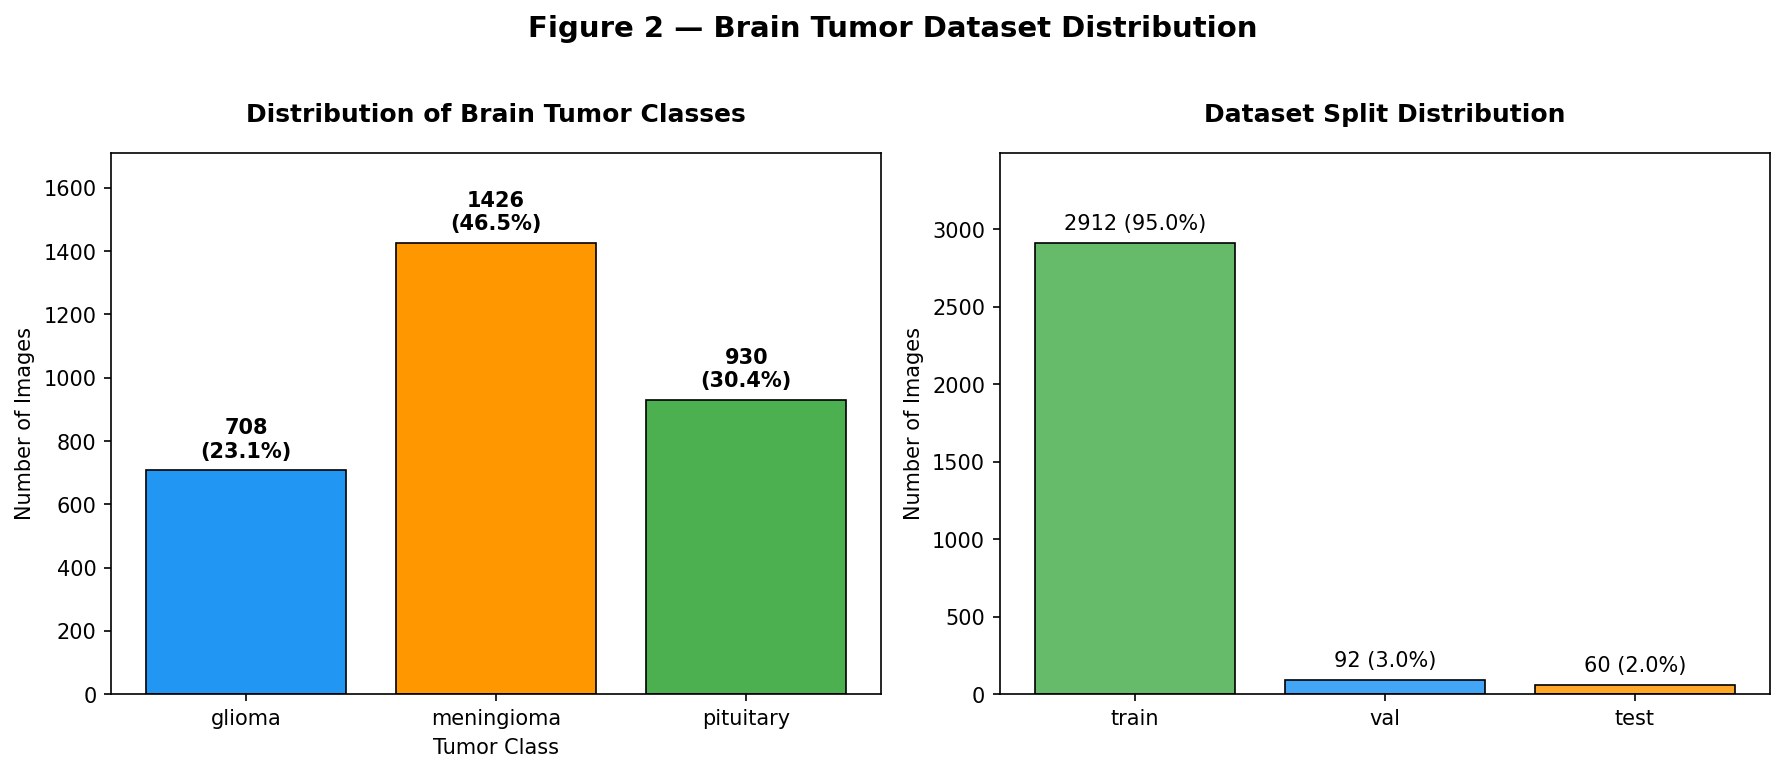

Saved: Fig_2_Dataset_Distribution.png


In [21]:
# Figure 2 — Dataset Distribution (bar chart with percentages)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Per-class distribution
counts = [total_class_counts[i] for i in range(NUM_CLASSES)]
pcts = [c / sum(counts) * 100 for c in counts]
colors = ['#2196F3', '#FF9800', '#4CAF50']

bars = axes[0].bar(CLASS_NAMES, counts, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_ylim(0, max(counts) * 1.20)  # add 20% headroom above tallest bar
for bar, pct, cnt in zip(bars, pcts, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts) * 0.02,
                 f'{cnt}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Distribution of Brain Tumor Classes', fontweight='bold', pad=15)
axes[0].set_ylabel('Number of Images')
axes[0].set_xlabel('Tumor Class')

# Per-split distribution
split_names = list(stats.keys())
split_counts = [stats[s]['images'] for s in split_names]
split_colors = ['#66BB6A', '#42A5F5', '#FFA726']

bars2 = axes[1].bar(split_names, split_counts, color=split_colors, edgecolor='black', linewidth=0.8)
axes[1].set_ylim(0, max(split_counts) * 1.20)  # add 20% headroom
for bar, cnt in zip(bars2, split_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(split_counts) * 0.02,
                 f'{cnt} ({cnt/TOTAL_IMAGES*100:.1f}%)', ha='center', va='bottom', fontsize=10)
axes[1].set_title('Dataset Split Distribution', fontweight='bold', pad=15)
axes[1].set_ylabel('Number of Images')

plt.suptitle('Figure 2 — Brain Tumor Dataset Distribution', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_2_Dataset_Distribution.png'), dpi=FIG_DPI)
plt.show()
print("Saved: Fig_2_Dataset_Distribution.png")

In [22]:
# Figure 3 — Brain Tumor Slices and Masks
# Find one sample per class
def find_sample_per_class(img_dir, lbl_dir):
    """Find one image per class."""
    samples = {}
    for lbl_file in sorted(glob.glob(os.path.join(lbl_dir, '*.txt'))):
        with open(lbl_file, 'r') as f:
            line = f.readline().strip()
        if not line:
            continue
        cls_id = int(line.split()[0])
        if cls_id not in samples:
            base = os.path.splitext(os.path.basename(lbl_file))[0]
            # Find matching image
            for ext in ['.png', '.jpg', '.jpeg']:
                img_path = os.path.join(img_dir, base + ext)
                if os.path.exists(img_path):
                    samples[cls_id] = (img_path, lbl_file)
                    break
        if len(samples) == NUM_CLASSES:
            break
    return samples

def parse_yolo_polygon(label_path, img_w, img_h):
    """Parse YOLO polygon label and return class_id and pixel-coordinate polygon."""
    polygons = []
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            points = np.array(coords).reshape(-1, 2)
            points[:, 0] *= img_w
            points[:, 1] *= img_h
            polygons.append((cls_id, points.astype(np.int32)))
    return polygons

samples = find_sample_per_class(TRAIN_IMG_DIR, TRAIN_LBL_DIR)
print(f"Found samples for {len(samples)} classes")

Found samples for 3 classes


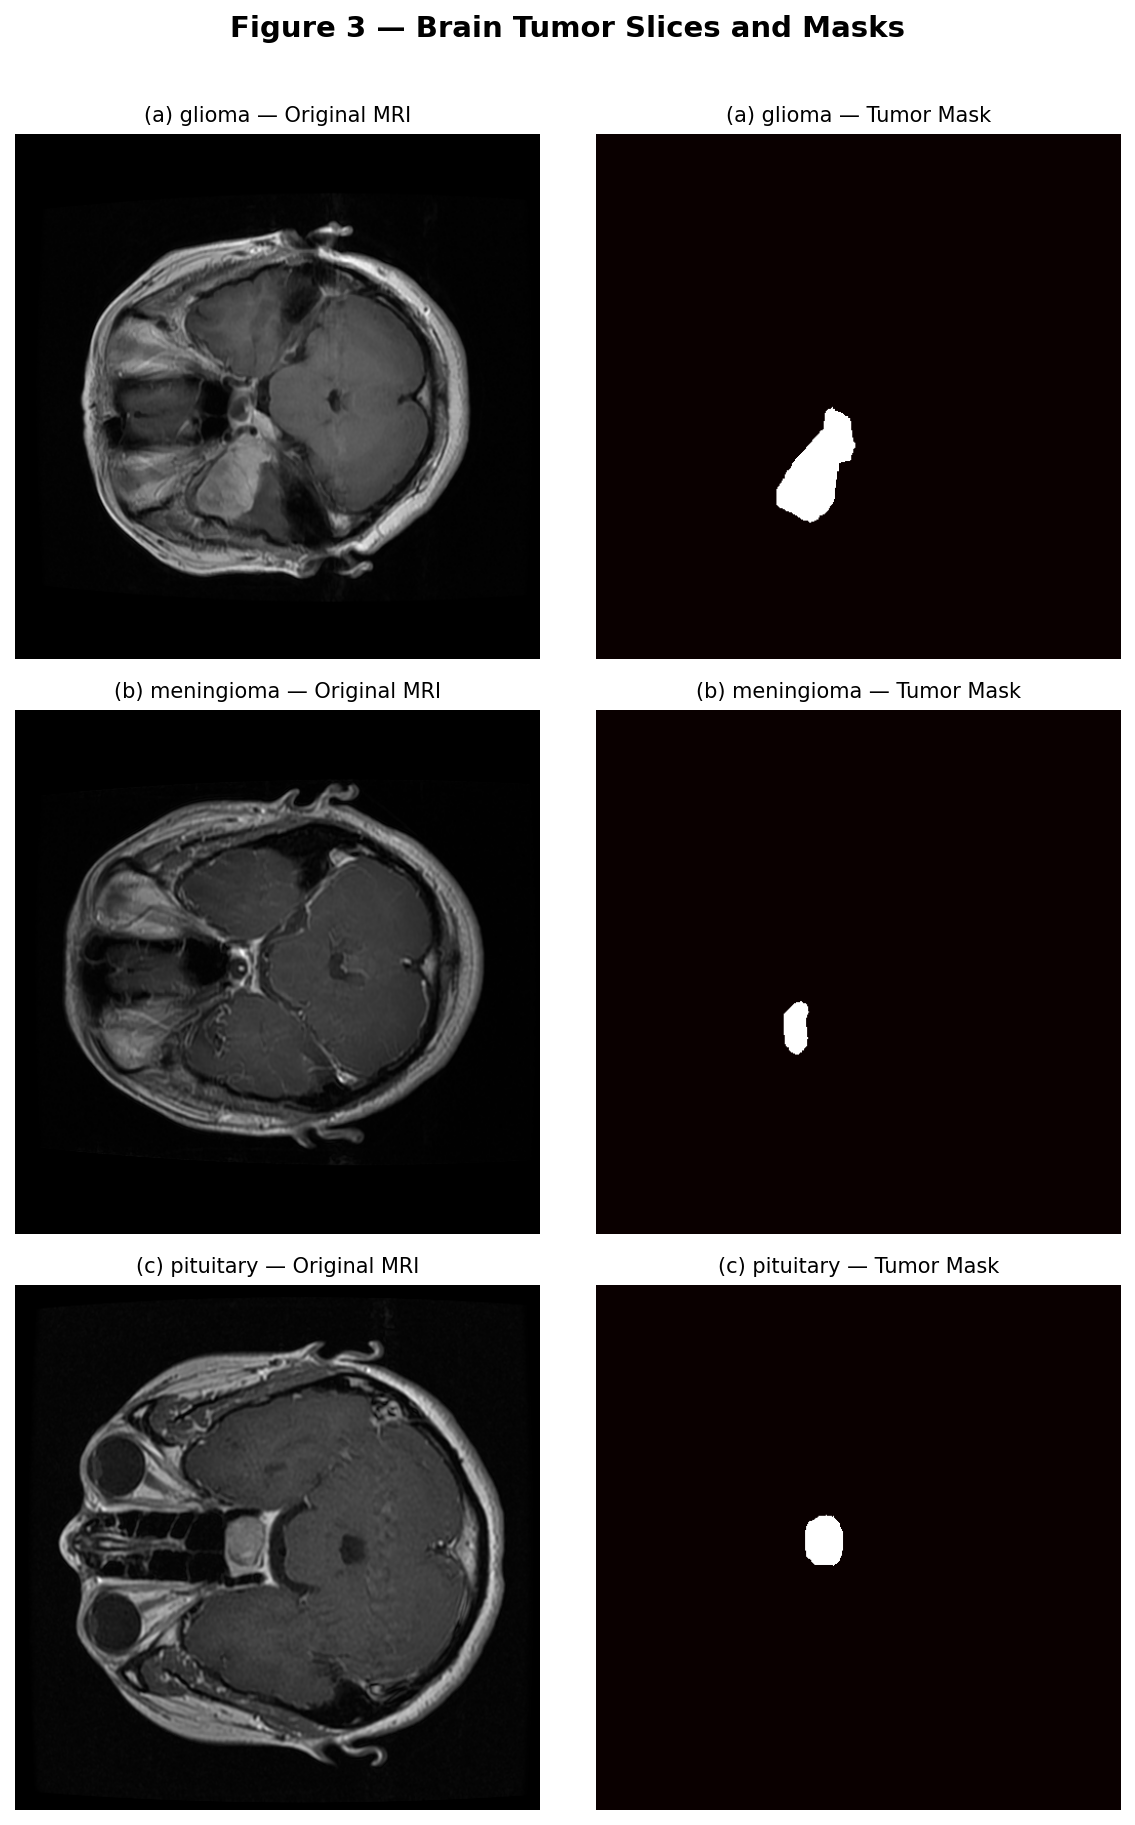

Saved: Fig_3_Combined.png


In [23]:
# Generate Figure 3 panels
fig, axes = plt.subplots(NUM_CLASSES, 2, figsize=(8, 4*NUM_CLASSES))
panel_labels = ['(a)', '(b)', '(c)']

for idx, cls_id in enumerate(sorted(samples.keys())):
    img_path, lbl_path = samples[cls_id]
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    
    # Create mask from polygon
    mask = np.zeros((h, w), dtype=np.uint8)
    polygons = parse_yolo_polygon(lbl_path, w, h)
    for _, pts in polygons:
        cv2.fillPoly(mask, [pts], 255)
    
    # Original MRI
    axes[idx, 0].imshow(img_rgb, cmap='gray')
    axes[idx, 0].set_title(f'{panel_labels[idx]} {CLASS_NAMES[cls_id]} — Original MRI', fontsize=10)
    axes[idx, 0].axis('off')
    
    # Mask
    axes[idx, 1].imshow(mask, cmap='hot')
    axes[idx, 1].set_title(f'{panel_labels[idx]} {CLASS_NAMES[cls_id]} — Tumor Mask', fontsize=10)
    axes[idx, 1].axis('off')
    
    # Save individual panels
    fig_panel, ax_panel = plt.subplots(1, 1, figsize=(4, 4))
    ax_panel.imshow(img_rgb, cmap='gray'); ax_panel.axis('off')
    fig_panel.savefig(os.path.join(RESULTS_DIR, 'figures', f'Fig_3_{chr(97+idx)}_MRI.png'), dpi=FIG_DPI)
    plt.close(fig_panel)

plt.suptitle('Figure 3 — Brain Tumor Slices and Masks', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_3_Combined.png'), dpi=FIG_DPI)
plt.show()
print("Saved: Fig_3_Combined.png")

## 8. Annotation Verification

### Figure 4 — Annotation Alignment Verification

Verify that YOLO polygon annotations correctly overlay on tumor regions.

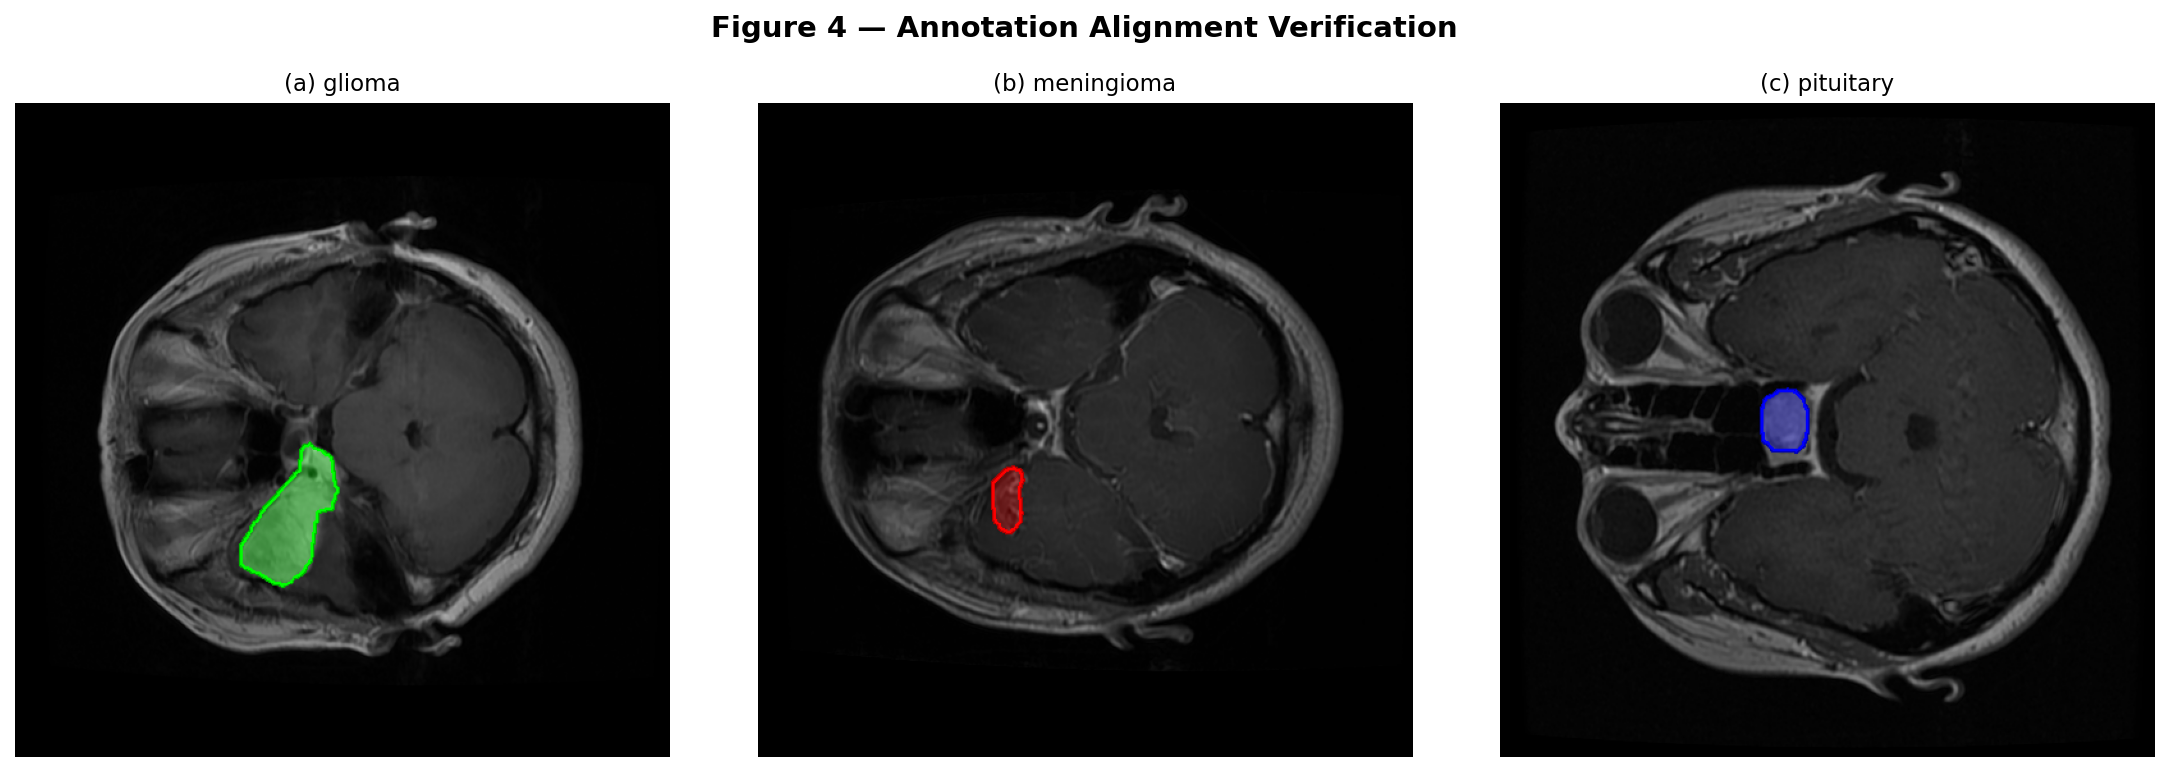

Saved: Fig_4_Combined.png


In [24]:
# Figure 4 — Annotation overlay verification
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(5*NUM_CLASSES, 5))
overlay_colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255)]  # green, red, blue

for idx, cls_id in enumerate(sorted(samples.keys())):
    img_path, lbl_path = samples[cls_id]
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    
    # Draw polygon overlay
    overlay = img_rgb.copy()
    polygons = parse_yolo_polygon(lbl_path, w, h)
    for _, pts in polygons:
        cv2.polylines(overlay, [pts], True, overlay_colors[idx], 2)
        mask_overlay = np.zeros_like(overlay)
        cv2.fillPoly(mask_overlay, [pts], overlay_colors[idx])
        overlay = cv2.addWeighted(overlay, 0.7, mask_overlay, 0.3, 0)
    
    axes[idx].imshow(overlay)
    axes[idx].set_title(f'({chr(97+idx)}) {CLASS_NAMES[cls_id]}', fontsize=11)
    axes[idx].axis('off')
    
    # Save individual panel
    fig_p, ax_p = plt.subplots(1, 1, figsize=(5, 5))
    ax_p.imshow(overlay); ax_p.axis('off')
    fig_p.savefig(os.path.join(RESULTS_DIR, 'figures', f'Fig_4_{chr(97+idx)}.png'), dpi=FIG_DPI)
    plt.close(fig_p)

plt.suptitle('Figure 4 — Annotation Alignment Verification', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_4_Combined.png'), dpi=FIG_DPI)
plt.show()
print("Saved: Fig_4_Combined.png")

In [25]:
# Annotation quality statistics
invalid_polygons = 0
total_polygons = 0
for lbl_file in glob.glob(os.path.join(TRAIN_LBL_DIR, '*.txt')):
    with open(lbl_file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            total_polygons += 1
            n_coords = len(parts) - 1
            if n_coords < 6:  # minimum 3 points (6 coords) for a valid polygon
                invalid_polygons += 1

print(f"Total polygons checked (train): {total_polygons}")
print(f"Invalid polygons (<3 vertices): {invalid_polygons}")
print(f"Annotation quality: {(total_polygons-invalid_polygons)/total_polygons*100:.1f}% valid")

Total polygons checked (train): 2912
Invalid polygons (<3 vertices): 0
Annotation quality: 100.0% valid


## 9. YOLOv11 Model Configuration

The blueprint describes the YOLO architecture elements:  
**Conv → C2f/C3 → SPPF → Upsample → Concat → Segment**

Below we load the actual model and extract its true architecture.

## 10. YOLOv26 Model Configuration

The blueprint describes YOLOv26 elements:  
**Conv → Concat → MaxPool → SPPCSP → Upsample → Segment**

Architecture details are extracted from the actual loaded model below.

In [26]:
# Load YOLO model
print(f"Loading model: {MODEL_NAME}")
try:
    model = YOLO(MODEL_NAME)
    print(f"[OK] Model loaded successfully: {MODEL_DISPLAY}")
except Exception as e:
    print(f"[ERROR] Failed to load {MODEL_NAME}: {e}")
    print("The requested checkpoint may not be available in this Ultralytics version.")
    print(f"Ultralytics version: {ultralytics.__version__}")
    raise

Loading model: yolo26x-seg.pt
[OK] Model loaded successfully: YOLOv26x-Seg


In [27]:
# Extract actual architecture information
model_info = model.info(verbose=False)

# Count layers and parameters
n_layers = 0
n_params = 0
module_types = Counter()

for name, module in model.model.named_modules():
    n_layers += 1
    n_params_mod = sum(p.numel() for p in module.parameters(recurse=False))
    if n_params_mod > 0:
        mod_type = type(module).__name__
        module_types[mod_type] += 1

total_params = sum(p.numel() for p in model.model.parameters())
trainable_params = sum(p.numel() for p in model.model.parameters() if p.requires_grad)

print(f"\n{'='*50}")
print(f"{MODEL_DISPLAY} Architecture Summary")
print(f"{'='*50}")
print(f"Total layers      : {n_layers}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")
print(f"\nModule types:")
for mod_type, count in module_types.most_common():
    print(f"  {mod_type:20s}: {count}")


YOLOv26x-Seg Architecture Summary
Total layers      : 767
Total parameters  : 70,693,800
Trainable params  : 0

Module types:
  Conv2d              : 217
  BatchNorm2d         : 198
  ConvTranspose2d     : 1


In [28]:
# Save architecture info
arch_data = {
    'Model': MODEL_DISPLAY,
    'Checkpoint': MODEL_NAME,
    'Total Layers': n_layers,
    'Total Parameters': f"{total_params:,}",
    'Trainable Parameters': f"{trainable_params:,}",
}
# Add module counts
for mod_type, count in module_types.most_common():
    arch_data[f'Module: {mod_type}'] = count

df_arch = pd.DataFrame([arch_data]).T.reset_index()
df_arch.columns = ['Property', 'Value']
df_arch.to_csv(os.path.join(RESULTS_DIR, 'architecture', 'Model_Architecture.csv'), index=False)
print(df_arch.to_string(index=False))

               Property          Value
                  Model   YOLOv26x-Seg
             Checkpoint yolo26x-seg.pt
           Total Layers            767
       Total Parameters     70,693,800
   Trainable Parameters              0
         Module: Conv2d            217
    Module: BatchNorm2d            198
Module: ConvTranspose2d              1


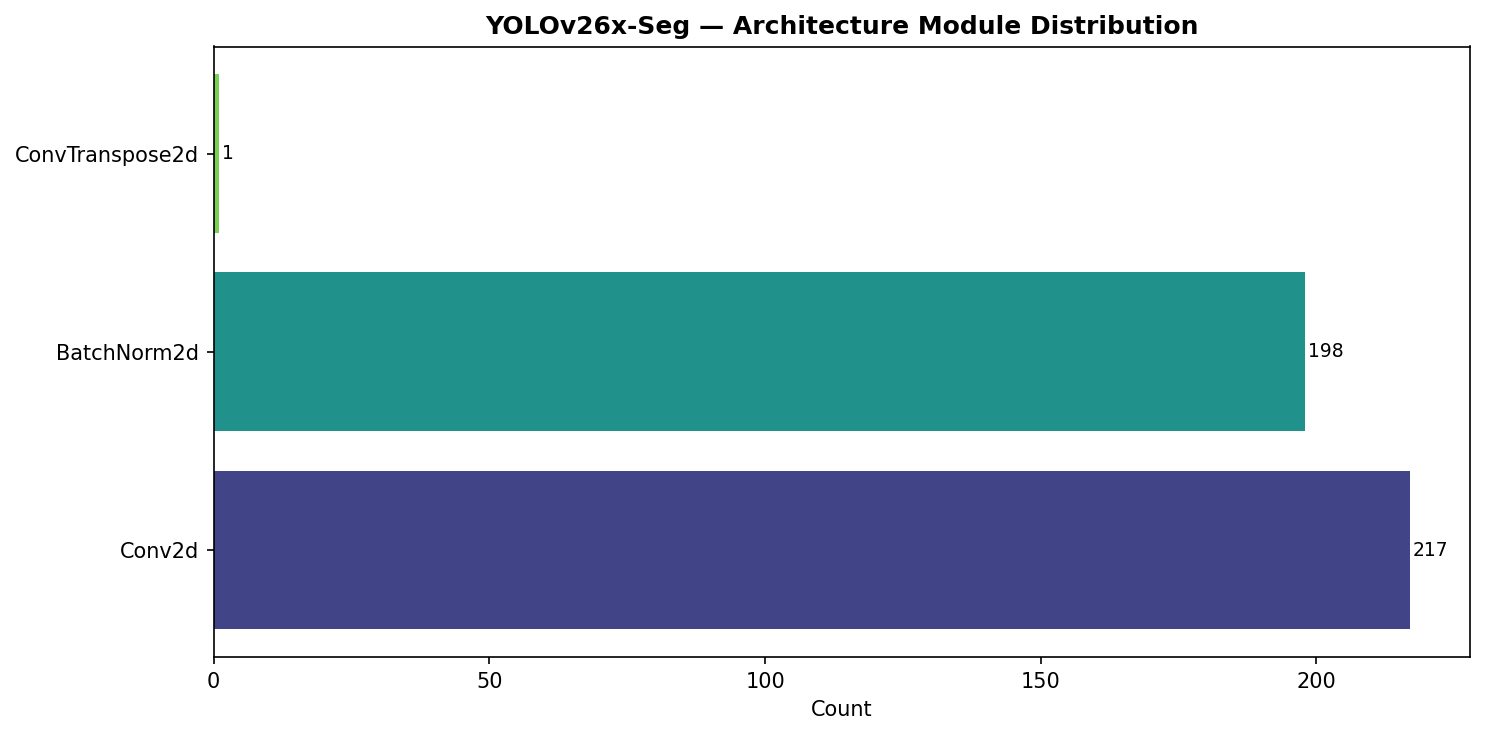

Saved: Fig_7_Architecture.png


In [29]:
# Architecture figure — layer type distribution
fig, ax = plt.subplots(figsize=(10, 5))
top_modules = dict(module_types.most_common(15))
bars = ax.barh(list(top_modules.keys()), list(top_modules.values()),
               color=plt.cm.viridis(np.linspace(0.2, 0.8, len(top_modules))))
ax.set_xlabel('Count')
ax.set_title(f'{MODEL_DISPLAY} — Architecture Module Distribution', fontweight='bold')
for bar, val in zip(bars, top_modules.values()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, str(val),
            va='center', fontsize=9)
plt.tight_layout()

fig_num = '6' if 'v11' in MODEL_NAME.lower() else '7'
plt.savefig(os.path.join(RESULTS_DIR, 'figures', f'Fig_{fig_num}_Architecture.png'), dpi=FIG_DPI)
plt.show()
print(f"Saved: Fig_{fig_num}_Architecture.png")

## 11. Model Training

Train the segmentation model on the brain tumor dataset.  
Data augmentation is applied **only to the training set**; validation and test remain unaugmented.

In [30]:
# Record training start time
train_start = time.time()

# Train model
results = model.train(
    data=WORKING_YAML,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    seed=SEED,
    device=DEVICE,
    project=os.path.join(RESULTS_DIR, 'training'),
    name='train_run',
    exist_ok=True,
    save=True,
    save_period=25,
    plots=True,
    verbose=True,
)

train_duration = time.time() - train_start
print(f"\nTraining completed in {train_duration/60:.1f} minutes")

Ultralytics 8.4.137 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26x-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_run, nbs=64, nms=False, op

In [31]:
# Locate best weights
TRAIN_DIR = os.path.join(RESULTS_DIR, 'training', 'train_run')
BEST_WEIGHTS = os.path.join(TRAIN_DIR, 'weights', 'best.pt')
LAST_WEIGHTS = os.path.join(TRAIN_DIR, 'weights', 'last.pt')

assert os.path.exists(BEST_WEIGHTS), f"Best weights not found at {BEST_WEIGHTS}"
print(f"Best weights : {BEST_WEIGHTS}")
print(f"Last weights : {LAST_WEIGHTS}")
print(f"Best.pt size : {os.path.getsize(BEST_WEIGHTS)/1e6:.1f} MB")

# Copy weights to model directory
shutil.copy2(BEST_WEIGHTS, os.path.join(RESULTS_DIR, 'model', 'best.pt'))
if os.path.exists(LAST_WEIGHTS):
    shutil.copy2(LAST_WEIGHTS, os.path.join(RESULTS_DIR, 'model', 'last.pt'))
print("Weights copied to model/ directory.")

Best weights : /kaggle/working/Brain_Tumor_Research_Results/YOLOv26x-Seg/training/train_run/weights/best.pt
Last weights : /kaggle/working/Brain_Tumor_Research_Results/YOLOv26x-Seg/training/train_run/weights/last.pt
Best.pt size : 141.7 MB
Weights copied to model/ directory.


## 12. Evaluation Parameters

Validate the trained model and extract all evaluation metrics:
- Confusion Matrix, Loss, Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1
- Both **box** and **mask** metrics for segmentation models

In [32]:
# Load best model and validate
best_model = YOLO(BEST_WEIGHTS)

val_start = time.time()
val_results = best_model.val(
    data=WORKING_YAML,
    split='val',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    save_json=True,
    project=os.path.join(RESULTS_DIR, 'validation'),
    name='val_run',
    exist_ok=True,
)
val_duration = time.time() - val_start
print(f"Validation completed in {val_duration:.1f} seconds")

Ultralytics 8.4.137 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26x-seg summary (fused): 207 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 126.2±13.1 MB/s, size: 119.1 KB)
val: Scanning /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/val/labels... 92 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 92/92 812.5it/s 0.1s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/val is not writable, cache not saved.
requirements: Ultralytics requirement ['faster-coco-eval>=1.6.7'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 2 packages in 965ms
Prepared 1 package in 237ms
Installed 1 package in 6ms
 + faster-coco-eval==1.8.0

requirements: AutoUpdate success ✅ 1.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

                 Class     Images  Instances      Box(P  

In [33]:
# Also run on test set
test_results = best_model.val(
    data=WORKING_YAML,
    split='test',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=os.path.join(RESULTS_DIR, 'testing'),
    name='test_run',
    exist_ok=True,
)
print("Test set evaluation completed.")

Ultralytics 8.4.137 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
WARNING ⚠️ val: Slow image access detected (ping: 1.1±1.0 ms, read: 20.5±5.8 MB/s, size: 97.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/test/labels... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 312.9it/s 0.2s.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mirajuddin1357/figshare-brain-tumor-seg/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.2it/s 1.6s3.1s
                   all         60         60      0.872      0.917      0.909      0.633      0.854      0.898      0.881      0.547
                glioma         14         14      0.863      0.929    

In [34]:
# Extract key metrics
# Box metrics
box_p = val_results.box.p       # per-class precision
box_r = val_results.box.r       # per-class recall
box_map50 = val_results.box.map50   # mAP@0.5
box_map = val_results.box.map       # mAP@0.5:0.95
box_ap50 = val_results.box.ap50     # per-class AP@0.5

# Mask metrics
mask_p = val_results.seg.p
mask_r = val_results.seg.r
mask_map50 = val_results.seg.map50
mask_map = val_results.seg.map
mask_ap50 = val_results.seg.ap50

print(f"\n{'='*60}")
print(f"{MODEL_DISPLAY} — Validation Results")
print(f"{'='*60}")
print(f"\nBOX METRICS:")
print(f"  Precision (all) : {np.mean(box_p):.4f}")
print(f"  Recall (all)    : {np.mean(box_r):.4f}")
print(f"  mAP@0.5         : {box_map50:.4f}")
print(f"  mAP@0.5:0.95    : {box_map:.4f}")
print(f"\nMASK METRICS:")
print(f"  Precision (all) : {np.mean(mask_p):.4f}")
print(f"  Recall (all)    : {np.mean(mask_r):.4f}")
print(f"  mAP@0.5         : {mask_map50:.4f}")
print(f"  mAP@0.5:0.95    : {mask_map:.4f}")

print(f"\nPer-class (Box):")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {name:12s}: P={box_p[i]:.4f}  R={box_r[i]:.4f}  AP50={box_ap50[i]:.4f}")


YOLOv26x-Seg — Validation Results

BOX METRICS:
  Precision (all) : 0.9631
  Recall (all)    : 0.8909
  mAP@0.5         : 0.9404
  mAP@0.5:0.95    : 0.6857

MASK METRICS:
  Precision (all) : 0.9533
  Recall (all)    : 0.8832
  mAP@0.5         : 0.9226
  mAP@0.5:0.95    : 0.6049

Per-class (Box):
  glioma      : P=0.9905  R=1.0000  AP50=0.9950
  meningioma  : P=0.9341  R=0.7442  AP50=0.8347
  pituitary   : P=0.9647  R=0.9286  AP50=0.9916


## 13. Training and Loss Analysis

Extract and plot training/validation losses from actual training output.

In [35]:
# Load training results CSV
results_csv = os.path.join(TRAIN_DIR, 'results.csv')
if os.path.exists(results_csv):
    df_results = pd.read_csv(results_csv)
    df_results.columns = [c.strip() for c in df_results.columns]
    print(f"Training results: {len(df_results)} epochs recorded")
    print(f"Columns: {list(df_results.columns)}")
else:
    print(f"[WARNING] results.csv not found at {results_csv}")
    df_results = None

Training results: 97 epochs recorded
Columns: ['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/l1_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss', 'val/l1_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


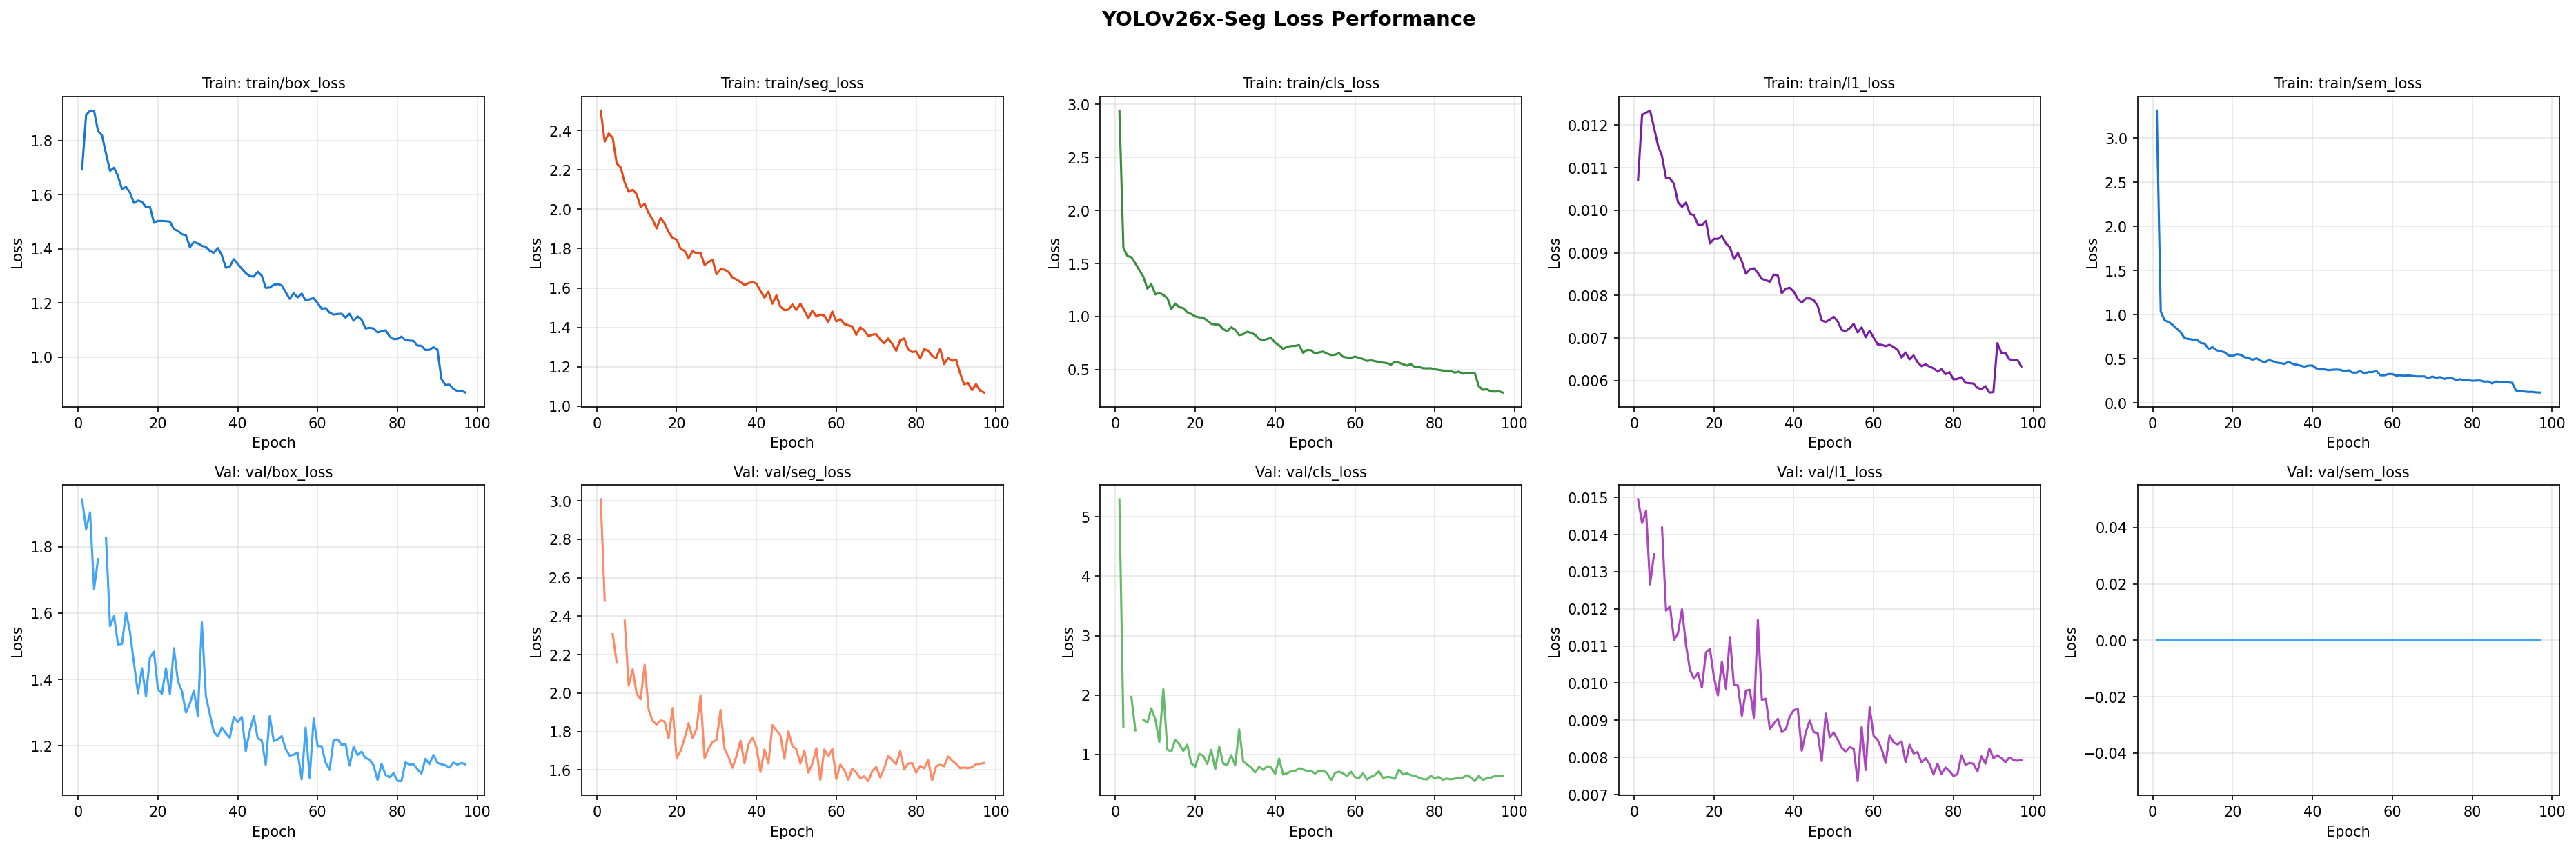

Saved: Fig_10_Loss_Performance.png


In [36]:
# Figure 8 — Loss Performance
if df_results is not None:
    # Identify loss columns
    loss_cols = [c for c in df_results.columns if 'loss' in c.lower()]
    train_losses = [c for c in loss_cols if 'val' not in c.lower()]
    val_losses = [c for c in loss_cols if 'val' in c.lower()]
    
    n_loss = max(len(train_losses), len(val_losses))
    fig, axes = plt.subplots(2, max(n_loss, 1), figsize=(5*max(n_loss, 1), 8))
    if n_loss == 1:
        axes = axes.reshape(2, 1)
    
    colors_t = ['#1976D2', '#E64A19', '#388E3C', '#7B1FA2']
    colors_v = ['#42A5F5', '#FF8A65', '#66BB6A', '#AB47BC']
    
    for i, col in enumerate(train_losses):
        if i < axes.shape[1]:
            axes[0, i].plot(df_results['epoch'], df_results[col], color=colors_t[i % 4], linewidth=1.5)
            axes[0, i].set_title(f'Train: {col}', fontsize=10)
            axes[0, i].set_xlabel('Epoch'); axes[0, i].set_ylabel('Loss')
            axes[0, i].grid(True, alpha=0.3)
    
    for i, col in enumerate(val_losses):
        if i < axes.shape[1]:
            axes[1, i].plot(df_results['epoch'], df_results[col], color=colors_v[i % 4], linewidth=1.5)
            axes[1, i].set_title(f'Val: {col}', fontsize=10)
            axes[1, i].set_xlabel('Epoch'); axes[1, i].set_ylabel('Loss')
            axes[1, i].grid(True, alpha=0.3)
    
    plt.suptitle(f'{MODEL_DISPLAY} Loss Performance', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_10_Loss_Performance.png'), dpi=FIG_DPI)
    plt.show()
    print("Saved: Fig_10_Loss_Performance.png")

In [37]:
# Table 2 — Loss Performance (final epoch values)
if df_results is not None:
    last_row = df_results.iloc[-1]
    loss_data = {'Loss Type': [], 'Value': []}
    for col in loss_cols:
        loss_data['Loss Type'].append(col)
        loss_data['Value'].append(f"{last_row[col]:.6f}")
    
    df_loss = pd.DataFrame(loss_data)
    df_loss.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_2_Loss_Performance.csv'), index=False)
    print("Table 2 — Loss Performance (Final Epoch)")
    print(df_loss.to_string(index=False))

Table 2 — Loss Performance (Final Epoch)
     Loss Type    Value
train/box_loss 0.869120
train/seg_loss 1.068920
train/cls_loss 0.283020
 train/l1_loss 0.006330
train/sem_loss 0.119370
  val/box_loss 1.143660
  val/seg_loss 1.635770
  val/cls_loss 0.632280
   val/l1_loss 0.007930
  val/sem_loss 0.000000


## 14. Precision Analysis

In [38]:
# Table 3 — Precision Performance
precision_data = {'Class': CLASS_NAMES + ['All'],
                  'Box Precision': list(box_p) + [np.mean(box_p)],
                  'Mask Precision': list(mask_p) + [np.mean(mask_p)]}
df_precision = pd.DataFrame(precision_data)
df_precision['Box Precision'] = df_precision['Box Precision'].apply(lambda x: f"{x:.4f}")
df_precision['Mask Precision'] = df_precision['Mask Precision'].apply(lambda x: f"{x:.4f}")

df_precision.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_3_Precision.csv'), index=False)
print("Table 3 — Precision Performance")
print(df_precision.to_string(index=False))

Table 3 — Precision Performance
     Class Box Precision Mask Precision
    glioma        0.9905         0.9905
meningioma        0.9341         0.9049
 pituitary        0.9647         0.9647
       All        0.9631         0.9533


In [39]:
# Copy precision-confidence curve from validation output
val_dir = os.path.join(RESULTS_DIR, 'validation', 'val_run')
for curve_name in ['P_curve.png', 'R_curve.png', 'F1_curve.png', 'PR_curve.png',
                   'confusion_matrix.png', 'confusion_matrix_normalized.png']:
    src = os.path.join(val_dir, curve_name)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(RESULTS_DIR, 'figures', f'{MODEL_TAG}_{curve_name}'))
        print(f"Copied: {curve_name}")

# Display precision curve
p_curve = os.path.join(val_dir, 'P_curve.png')
if os.path.exists(p_curve):
    img = plt.imread(p_curve)
    plt.figure(figsize=(10, 7))
    plt.imshow(img); plt.axis('off')
    plt.title(f'Figure 9 — {MODEL_DISPLAY} Precision-Confidence Curve', fontweight='bold')
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_9_Precision_Confidence.png'), dpi=FIG_DPI)
    plt.show()

Copied: confusion_matrix.png
Copied: confusion_matrix_normalized.png


## 15. Recall Analysis

In [40]:
# Table 4 — Recall Performance
recall_data = {'Class': CLASS_NAMES + ['All'],
               'Box Recall': list(box_r) + [np.mean(box_r)],
               'Mask Recall': list(mask_r) + [np.mean(mask_r)]}
df_recall = pd.DataFrame(recall_data)
df_recall['Box Recall'] = df_recall['Box Recall'].apply(lambda x: f"{x:.4f}")
df_recall['Mask Recall'] = df_recall['Mask Recall'].apply(lambda x: f"{x:.4f}")

df_recall.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_4_Recall.csv'), index=False)
print("Table 4 — Recall Performance")
print(df_recall.to_string(index=False))

Table 4 — Recall Performance
     Class Box Recall Mask Recall
    glioma     1.0000      1.0000
meningioma     0.7442      0.7209
 pituitary     0.9286      0.9286
       All     0.8909      0.8832


In [41]:
# Display recall curve
r_curve = os.path.join(val_dir, 'R_curve.png')
if os.path.exists(r_curve):
    img = plt.imread(r_curve)
    plt.figure(figsize=(10, 7))
    plt.imshow(img); plt.axis('off')
    plt.title(f'Figure 10 — {MODEL_DISPLAY} Recall-Confidence Curve', fontweight='bold')
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_10_Recall_Confidence.png'), dpi=FIG_DPI)
    plt.show()

## 16. mAP@0.5 Analysis

In [42]:
# Table 5 — mAP@0.5
map50_data = {
    'Class': CLASS_NAMES + ['All'],
    'Box mAP@0.5': list(box_ap50) + [box_map50],
    'Mask mAP@0.5': list(mask_ap50) + [mask_map50]
}
df_map50 = pd.DataFrame(map50_data)
df_map50['Box mAP@0.5'] = df_map50['Box mAP@0.5'].apply(lambda x: f"{x:.4f}")
df_map50['Mask mAP@0.5'] = df_map50['Mask mAP@0.5'].apply(lambda x: f"{x:.4f}")

df_map50.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_5_mAP50.csv'), index=False)
print("Table 5 — Mean Average Precision (mAP@0.5)")
print(df_map50.to_string(index=False))

Table 5 — Mean Average Precision (mAP@0.5)
     Class Box mAP@0.5 Mask mAP@0.5
    glioma      0.9950       0.9950
meningioma      0.8347       0.7814
 pituitary      0.9916       0.9916
       All      0.9404       0.9226


## 17. mAP@0.5:0.95 Analysis

In [43]:
# Table 6 — mAP@0.5:0.95
# Per-class mAP@0.5:0.95
box_ap = val_results.box.ap     # shape: (nc, 10) — AP at each IoU threshold
mask_ap = val_results.seg.ap

box_map_per_class = box_ap.mean(axis=1) if box_ap.ndim > 1 else box_ap
mask_map_per_class = mask_ap.mean(axis=1) if mask_ap.ndim > 1 else mask_ap

map95_data = {
    'Class': CLASS_NAMES + ['All'],
    'Box mAP@0.5:0.95': list(box_map_per_class) + [box_map],
    'Mask mAP@0.5:0.95': list(mask_map_per_class) + [mask_map]
}
df_map95 = pd.DataFrame(map95_data)
df_map95['Box mAP@0.5:0.95'] = df_map95['Box mAP@0.5:0.95'].apply(lambda x: f"{x:.4f}")
df_map95['Mask mAP@0.5:0.95'] = df_map95['Mask mAP@0.5:0.95'].apply(lambda x: f"{x:.4f}")

df_map95.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_6_mAP50_95.csv'), index=False)
print("Table 6 — Mean Average Precision (mAP@0.5:0.95)")
print(df_map95.to_string(index=False))

Table 6 — Mean Average Precision (mAP@0.5:0.95)
     Class Box mAP@0.5:0.95 Mask mAP@0.5:0.95
    glioma           0.7921            0.7276
meningioma           0.5195            0.4493
 pituitary           0.7456            0.6377
       All           0.6857            0.6049


## 18. F1-Confidence Analysis

In [44]:
# Display F1-confidence curve
f1_curve = os.path.join(val_dir, 'F1_curve.png')
if os.path.exists(f1_curve):
    img = plt.imread(f1_curve)
    plt.figure(figsize=(10, 7))
    plt.imshow(img); plt.axis('off')
    plt.title(f'Figure 11 — {MODEL_DISPLAY} F1-Confidence Curve', fontweight='bold')
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_11_F1_Confidence.png'), dpi=FIG_DPI)
    plt.show()

# Calculate F1 scores
f1_box = 2 * (box_p * box_r) / (box_p + box_r + 1e-8)
f1_mask = 2 * (mask_p * mask_r) / (mask_p + mask_r + 1e-8)

f1_data = {'Class': CLASS_NAMES + ['All'],
           'Box F1': list(f1_box) + [np.mean(f1_box)],
           'Mask F1': list(f1_mask) + [np.mean(f1_mask)]}
df_f1 = pd.DataFrame(f1_data)
df_f1['Box F1'] = df_f1['Box F1'].apply(lambda x: f"{x:.4f}")
df_f1['Mask F1'] = df_f1['Mask F1'].apply(lambda x: f"{x:.4f}")
df_f1.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_F1_Score.csv'), index=False)
print("F1 Scores")
print(df_f1.to_string(index=False))

F1 Scores
     Class Box F1 Mask F1
    glioma 0.9952  0.9952
meningioma 0.8284  0.8025
 pituitary 0.9463  0.9463
       All 0.9233  0.9147


## 19. Confusion Matrix

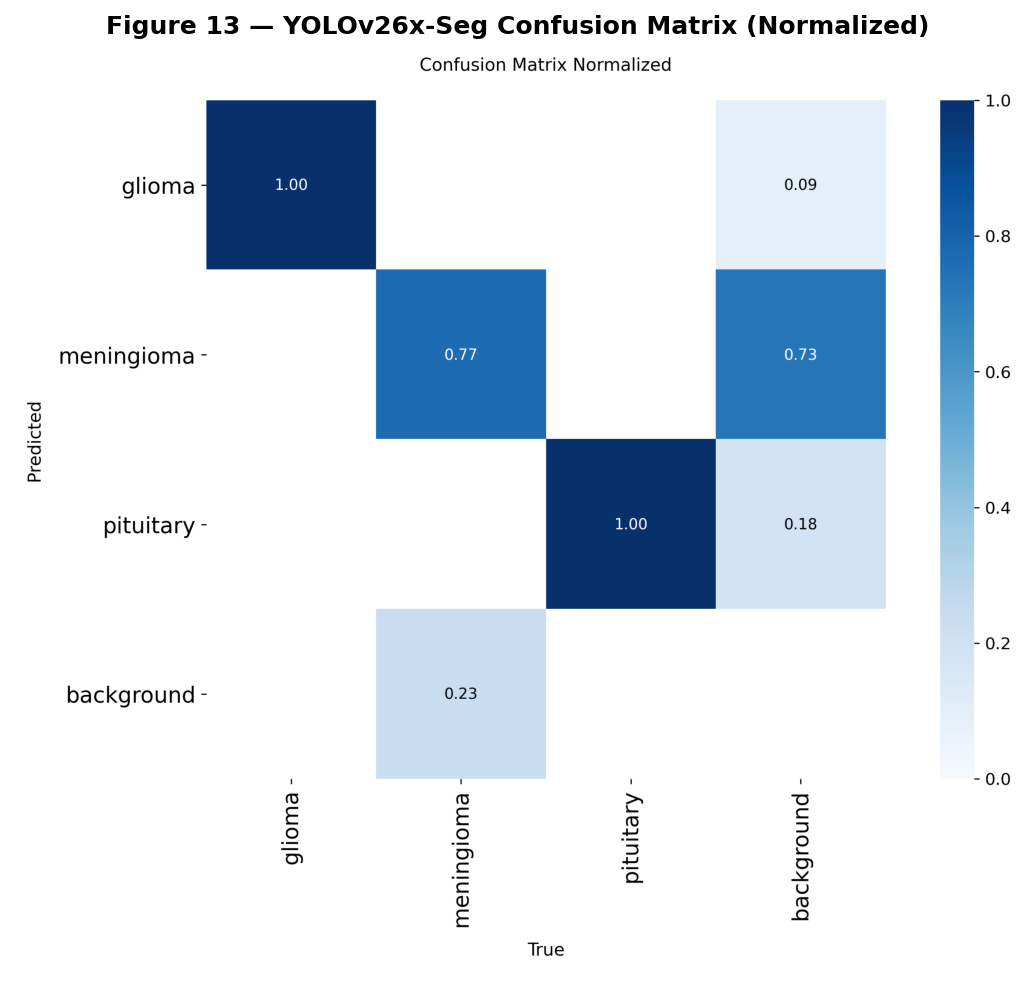

Saved: Fig_13_Confusion_Matrix.png


In [45]:
# Display confusion matrix
cm_path = os.path.join(val_dir, 'confusion_matrix_normalized.png')
if not os.path.exists(cm_path):
    cm_path = os.path.join(val_dir, 'confusion_matrix.png')

if os.path.exists(cm_path):
    img = plt.imread(cm_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(img); plt.axis('off')
    plt.title(f'Figure 13 — {MODEL_DISPLAY} Confusion Matrix (Normalized)', fontweight='bold')
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_13_Confusion_Matrix.png'), dpi=FIG_DPI)
    plt.show()
    print("Saved: Fig_13_Confusion_Matrix.png")

## 20. Segmentation Performance

Calculate pixel-level segmentation metrics: **IoU** and **Dice** coefficient  
by comparing predicted masks against ground-truth masks.

In [46]:
# Run inference on validation set for segmentation metrics
def compute_mask_iou_dice(pred_mask, gt_mask):
    """Compute IoU and Dice between two binary masks."""
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = np.logical_or(pred_mask, gt_mask).sum()
    iou = intersection / (union + 1e-8)
    dice = 2 * intersection / (pred_mask.sum() + gt_mask.sum() + 1e-8)
    return iou, dice

# Collect per-class segmentation metrics
seg_metrics = {cls: {'iou': [], 'dice': []} for cls in CLASS_NAMES}

# Process a subset for efficiency
val_images = sorted(glob.glob(os.path.join(VAL_IMG_DIR, '*.[pj]*')))[:100]
print(f"Computing Dice/IoU on {len(val_images)} validation images...")

for img_path in val_images:
    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w = img.shape[:2]
    
    # Ground truth mask
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(VAL_LBL_DIR, base + '.txt')
    if not os.path.exists(lbl_path):
        continue
    
    gt_polygons = parse_yolo_polygon(lbl_path, w, h)
    if not gt_polygons:
        continue
    
    gt_cls = gt_polygons[0][0]
    gt_mask = np.zeros((h, w), dtype=np.uint8)
    for _, pts in gt_polygons:
        cv2.fillPoly(gt_mask, [pts], 1)
    
    # Prediction
    result = best_model.predict(img_path, imgsz=IMG_SIZE, conf=CONF_THRESHOLD,
                                device=DEVICE, verbose=False)[0]
    
    if result.masks is not None and len(result.masks) > 0:
        # Get best prediction mask
        pred_mask_tensor = result.masks.data[0].cpu().numpy()
        pred_mask = cv2.resize(pred_mask_tensor.astype(np.float32), (w, h))
        pred_mask = (pred_mask > 0.5).astype(np.uint8)
        
        iou, dice = compute_mask_iou_dice(pred_mask, gt_mask)
        cls_name = CLASS_NAMES[gt_cls]
        seg_metrics[cls_name]['iou'].append(iou)
        seg_metrics[cls_name]['dice'].append(dice)

print("Segmentation metrics computed.")

Computing Dice/IoU on 92 validation images...
Segmentation metrics computed.


In [47]:
# Segmentation metrics summary table
seg_rows = []
for cls_name in CLASS_NAMES:
    ious = seg_metrics[cls_name]['iou']
    dices = seg_metrics[cls_name]['dice']
    if len(ious) > 0:
        seg_rows.append({
            'Class': cls_name,
            'N': len(ious),
            'IoU Mean': f"{np.mean(ious):.4f}",
            'IoU Median': f"{np.median(ious):.4f}",
            'IoU Std': f"{np.std(ious):.4f}",
            'IoU Min': f"{np.min(ious):.4f}",
            'IoU Max': f"{np.max(ious):.4f}",
            'Dice Mean': f"{np.mean(dices):.4f}",
            'Dice Median': f"{np.median(dices):.4f}",
            'Dice Std': f"{np.std(dices):.4f}",
            'Dice Min': f"{np.min(dices):.4f}",
            'Dice Max': f"{np.max(dices):.4f}",
        })

# Overall
all_ious = [v for cls in seg_metrics.values() for v in cls['iou']]
all_dices = [v for cls in seg_metrics.values() for v in cls['dice']]
if all_ious:
    seg_rows.append({
        'Class': 'All', 'N': len(all_ious),
        'IoU Mean': f"{np.mean(all_ious):.4f}", 'IoU Median': f"{np.median(all_ious):.4f}",
        'IoU Std': f"{np.std(all_ious):.4f}", 'IoU Min': f"{np.min(all_ious):.4f}",
        'IoU Max': f"{np.max(all_ious):.4f}", 'Dice Mean': f"{np.mean(all_dices):.4f}",
        'Dice Median': f"{np.median(all_dices):.4f}", 'Dice Std': f"{np.std(all_dices):.4f}",
        'Dice Min': f"{np.min(all_dices):.4f}", 'Dice Max': f"{np.max(all_dices):.4f}"
    })

df_seg = pd.DataFrame(seg_rows)
df_seg.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_Segmentation_Metrics.csv'), index=False)
df_seg.to_excel(os.path.join(RESULTS_DIR, 'tables', 'Table_Segmentation_Metrics.xlsx'), index=False)
print("Segmentation Metrics (IoU & Dice)")
print(df_seg.to_string(index=False))

Segmentation Metrics (IoU & Dice)
     Class  N IoU Mean IoU Median IoU Std IoU Min IoU Max Dice Mean Dice Median Dice Std Dice Min Dice Max
    glioma 21   0.8589     0.8648  0.0599  0.7083  0.9361    0.9230      0.9275   0.0356   0.8292   0.9670
meningioma 39   0.6959     0.7962  0.2343  0.0000  0.9094    0.7907      0.8865   0.2205   0.0000   0.9525
 pituitary 28   0.8283     0.8485  0.0977  0.5220  0.9232    0.9026      0.9181   0.0657   0.6859   0.9601
       All 88   0.7769     0.8329  0.1832  0.0000  0.9361    0.8579      0.9088   0.1639   0.0000   0.9670


## 21. Prediction Visualization

Show real prediction examples with original MRI, ground truth, prediction, and mask.

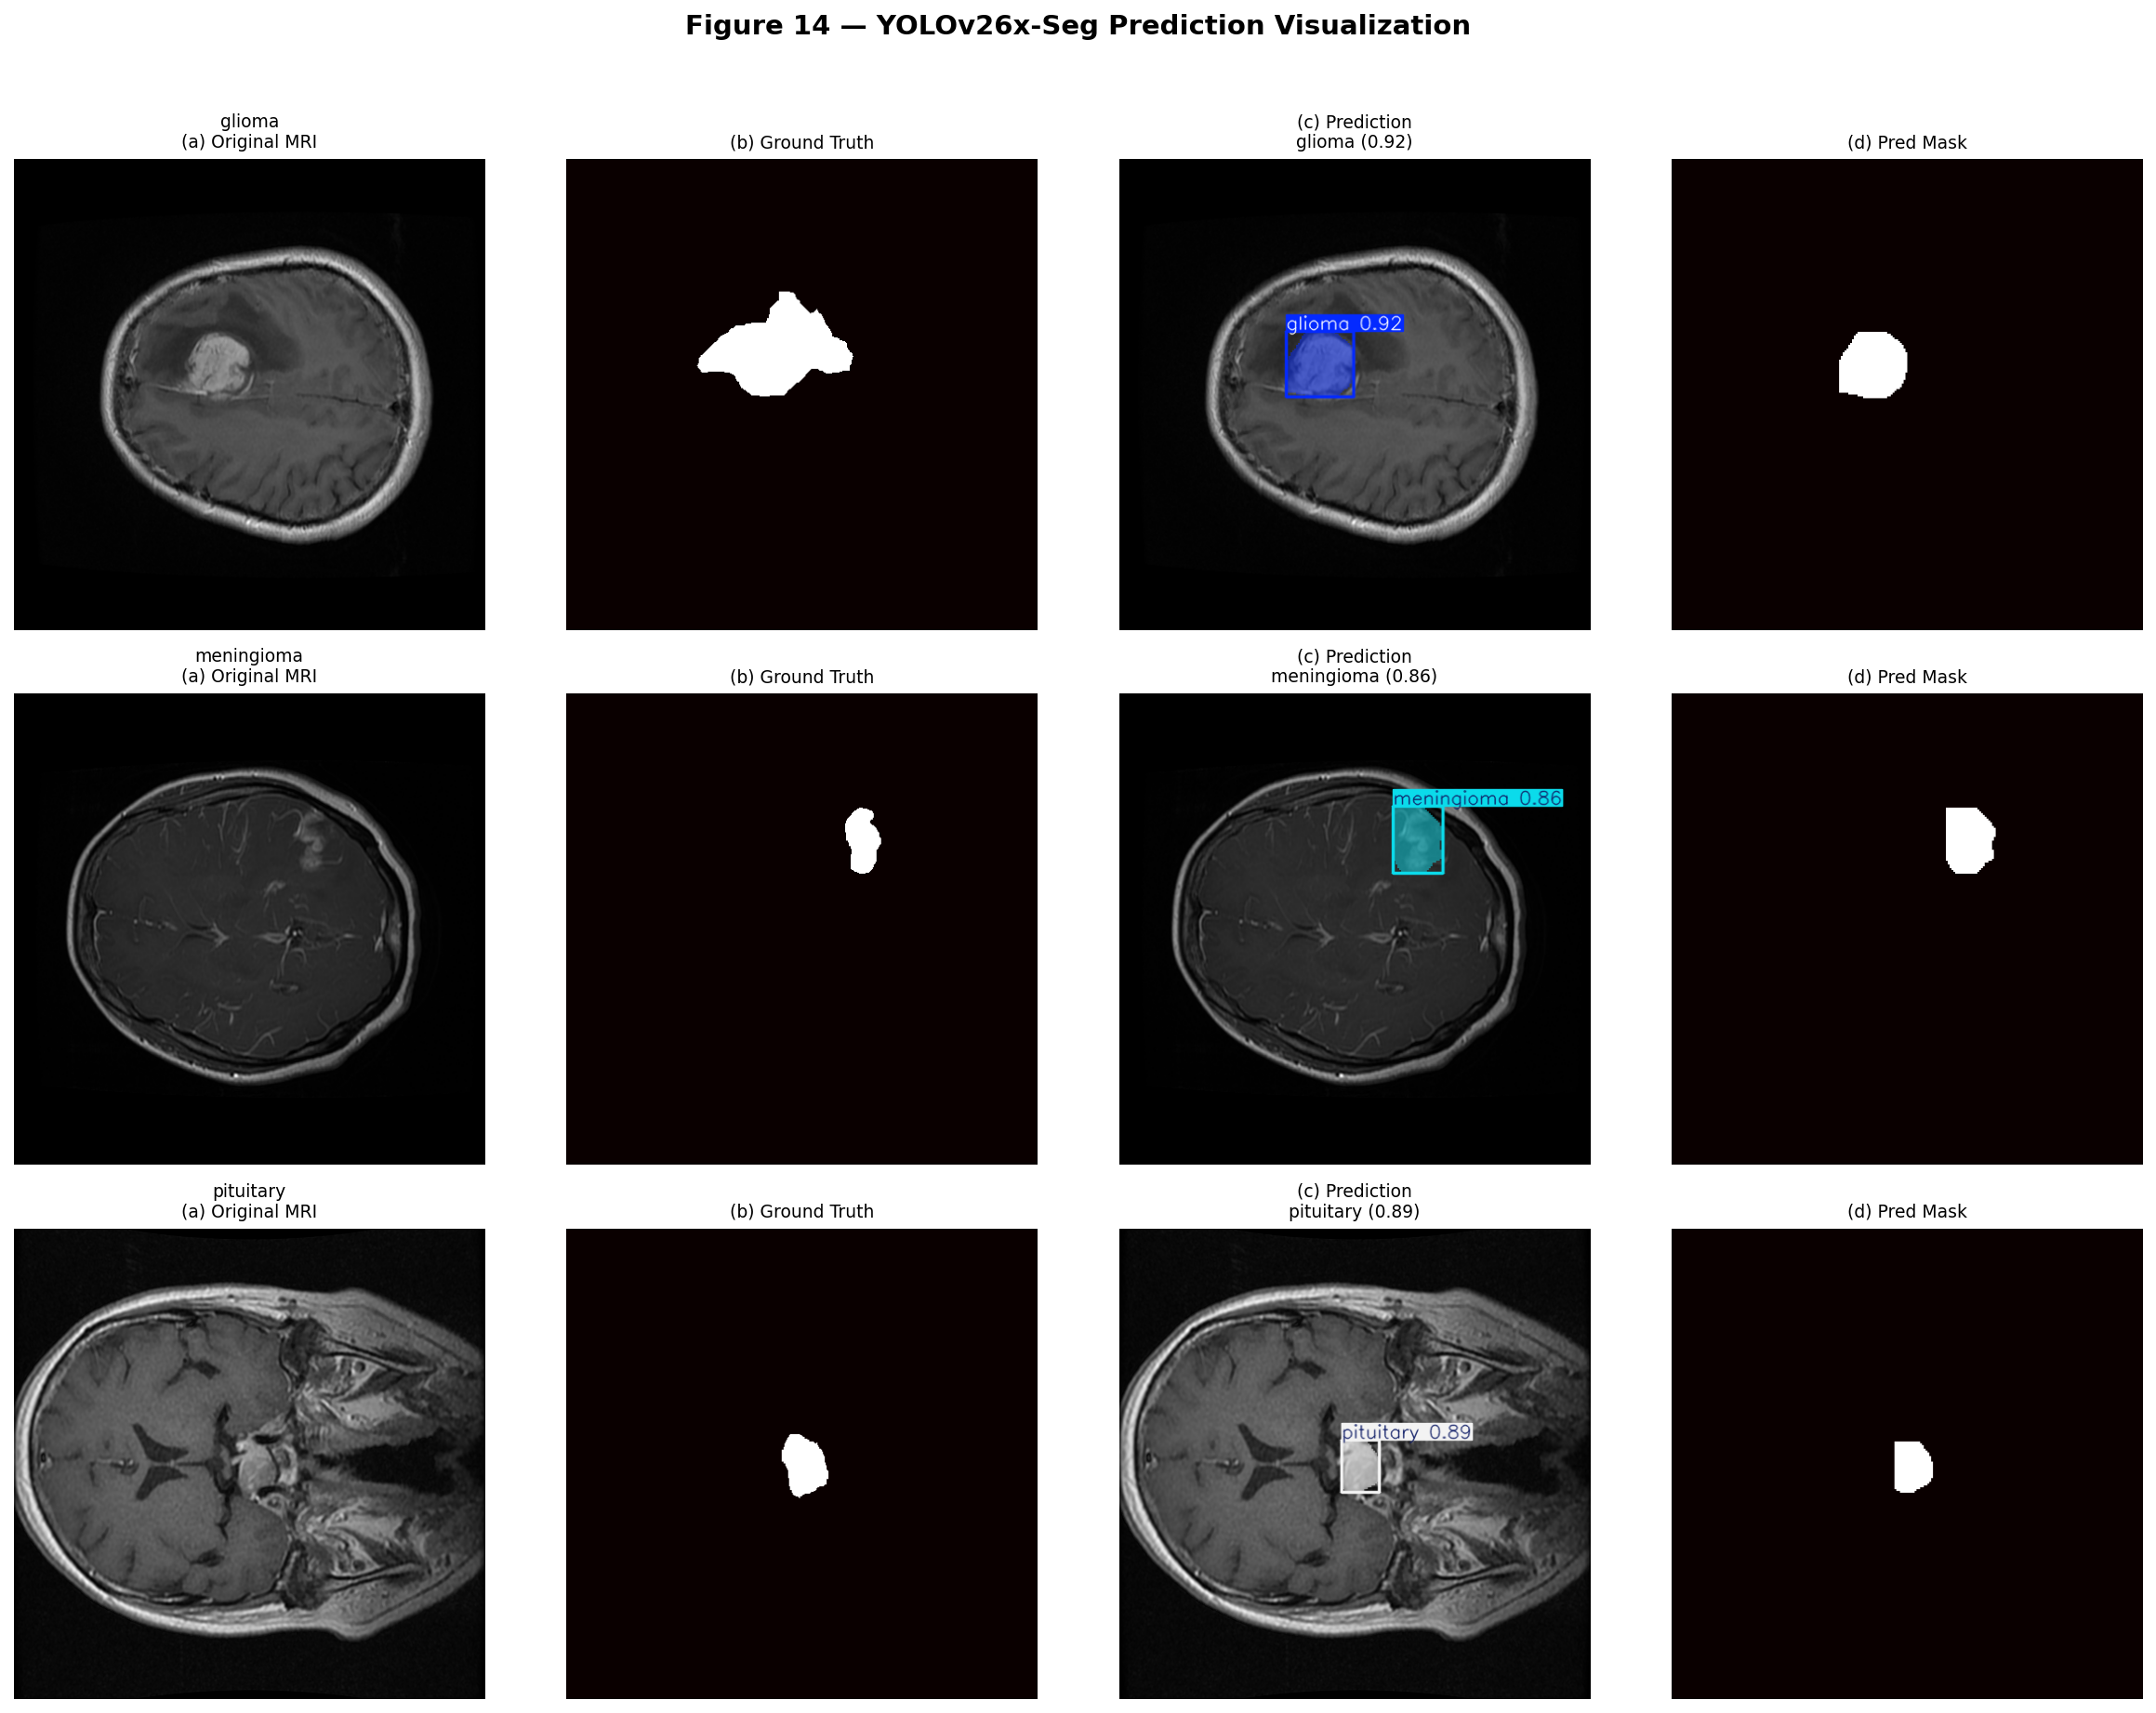

Saved: Fig_14_Predictions.png


In [48]:
# Select sample images for prediction visualization (one per class from test set)
test_samples = find_sample_per_class(TEST_IMG_DIR, TEST_LBL_DIR)
if len(test_samples) < NUM_CLASSES:
    test_samples = find_sample_per_class(VAL_IMG_DIR, VAL_LBL_DIR)

fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(16, 4*NUM_CLASSES))
col_titles = ['(a) Original MRI', '(b) Ground Truth', '(c) Prediction', '(d) Pred Mask']

for idx, cls_id in enumerate(sorted(test_samples.keys())):
    img_path, lbl_path = test_samples[cls_id]
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    
    # Ground truth mask
    gt_mask = np.zeros((h, w), dtype=np.uint8)
    for _, pts in parse_yolo_polygon(lbl_path, w, h):
        cv2.fillPoly(gt_mask, [pts], 255)
    
    # Prediction
    result = best_model.predict(img_path, imgsz=IMG_SIZE, conf=CONF_THRESHOLD,
                                device=DEVICE, verbose=False)[0]
    
    # Original
    axes[idx, 0].imshow(img_rgb, cmap='gray')
    axes[idx, 0].set_title(f'{CLASS_NAMES[cls_id]}\n{col_titles[0]}', fontsize=9)
    axes[idx, 0].axis('off')
    
    # Ground truth
    axes[idx, 1].imshow(gt_mask, cmap='hot')
    axes[idx, 1].set_title(col_titles[1], fontsize=9)
    axes[idx, 1].axis('off')
    
    # Prediction overlay
    pred_img = result.plot()
    axes[idx, 2].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
    if result.boxes is not None and len(result.boxes) > 0:
        conf = result.boxes.conf[0].item()
        pred_cls = int(result.boxes.cls[0].item())
        axes[idx, 2].set_title(f'{col_titles[2]}\n{CLASS_NAMES[pred_cls]} ({conf:.2f})', fontsize=9)
    else:
        axes[idx, 2].set_title(f'{col_titles[2]}\nNo detection', fontsize=9)
    axes[idx, 2].axis('off')
    
    # Predicted mask
    if result.masks is not None and len(result.masks) > 0:
        pred_m = result.masks.data[0].cpu().numpy()
        pred_m = cv2.resize(pred_m, (w, h))
        axes[idx, 3].imshow(pred_m, cmap='hot')
    else:
        axes[idx, 3].imshow(np.zeros((h, w)), cmap='gray')
    axes[idx, 3].set_title(col_titles[3], fontsize=9)
    axes[idx, 3].axis('off')

plt.suptitle(f'Figure 14 — {MODEL_DISPLAY} Prediction Visualization', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_14_Predictions.png'), dpi=FIG_DPI)
plt.show()
print("Saved: Fig_14_Predictions.png")

## 21.5 Detection / Inference Time

In [49]:
# Measure inference time on test set
test_images = sorted(glob.glob(os.path.join(TEST_IMG_DIR, '*.[pj]*')))[:50]
preprocess_times = []
inference_times = []
postprocess_times = []

# Warmup
_ = best_model.predict(test_images[0], imgsz=IMG_SIZE, device=DEVICE, verbose=False)

for img_path in test_images:
    result = best_model.predict(img_path, imgsz=IMG_SIZE, device=DEVICE, verbose=False)[0]
    speed = result.speed  # dict with preprocess, inference, postprocess in ms
    preprocess_times.append(speed.get('preprocess', 0))
    inference_times.append(speed.get('inference', 0))
    postprocess_times.append(speed.get('postprocess', 0))

avg_pre = np.mean(preprocess_times)
avg_inf = np.mean(inference_times)
avg_post = np.mean(postprocess_times)
avg_total = avg_pre + avg_inf + avg_post
fps = 1000.0 / avg_total if avg_total > 0 else 0

timing_data = {
    'Metric': ['Preprocess (ms)', 'Inference (ms)', 'Postprocess/NMS (ms)', 'Total (ms)', 'FPS',
               'Images Tested', 'Image Size', 'GPU'],
    'Value': [f"{avg_pre:.2f}", f"{avg_inf:.2f}", f"{avg_post:.2f}", f"{avg_total:.2f}", f"{fps:.1f}",
              len(test_images), IMG_SIZE,
              torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU']
}
df_timing = pd.DataFrame(timing_data)
df_timing.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_Inference_Time.csv'), index=False)
print("Inference Time")
print(df_timing.to_string(index=False))

Inference Time
              Metric    Value
     Preprocess (ms)     0.50
      Inference (ms)    19.74
Postprocess/NMS (ms)     0.88
          Total (ms)    21.12
                 FPS     47.4
       Images Tested       50
          Image Size      256
                 GPU Tesla T4


## 22. Grad-CAM Explainability

### Core Contribution: Gradient-weighted Class Activation Mapping

**Mathematical Formulation:**

Grad-CAM weights: $\alpha_k^c = \text{GAP}\left(\frac{\partial y^c}{\partial A^k}\right)$

Grad-CAM heatmap: $L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$

**Pipeline:** Input MRI → Forward pass → Target layer activations → Backward pass → 
Gradient computation → GAP weights → Weighted combination → ReLU → Normalization → 
Bilinear upsampling → Jet colormap → Alpha overlay

In [50]:
# Grad-CAM implementation for YOLO
class YOLOGradCAM:
    """Grad-CAM for Ultralytics YOLO models."""
    def __init__(self, model, target_layer_idx=None):
        self.model = model.model
        self.activations = None
        self.gradients = None
        
        # Auto-select target layer (last conv before detection head)
        self.target_layer = self._find_target_layer(target_layer_idx)
        self.target_layer_name = type(self.target_layer).__name__
        
        # Register hooks
        self.target_layer.register_forward_hook(self._forward_hook)
        self.target_layer.register_full_backward_hook(self._backward_hook)
    
    def _find_target_layer(self, idx=None):
        """Find appropriate target conv layer."""
        conv_layers = []
        for name, module in self.model.named_modules():
            if isinstance(module, (torch.nn.Conv2d,)):
                conv_layers.append((name, module))
        
        if idx is not None and idx < len(conv_layers):
            name, layer = conv_layers[idx]
        else:
            # Use the last conv layer in the backbone (before detect head)
            # Try to find a layer around 2/3 through the network
            target_idx = len(conv_layers) * 2 // 3
            name, layer = conv_layers[target_idx]
        
        self.target_layer_idx = target_idx if idx is None else idx
        self.target_layer_full_name = name
        print(f"Grad-CAM target layer: {name} ({type(layer).__name__})")
        return layer
    
    def _forward_hook(self, module, input, output):
        self.activations = output.detach()
    
    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate(self, img_tensor, class_idx=None):
        """Generate Grad-CAM heatmap."""
        self.model.eval()
        img_tensor.requires_grad_(True)
        
        # Forward pass
        output = self.model(img_tensor)
        
        # Get score for target class
        if isinstance(output, (tuple, list)):
            # YOLO returns multiple outputs; use first detection output
            det_output = output[0] if isinstance(output[0], torch.Tensor) else output[0][0]
        else:
            det_output = output
        
        # Use max score as target
        if class_idx is not None:
            score = det_output[..., 4 + class_idx].max()
        else:
            score = det_output[..., 4:].max()
        
        # Backward pass
        self.model.zero_grad()
        score.backward(retain_graph=True)
        
        if self.gradients is None or self.activations is None:
            return None
        
        # Grad-CAM: alpha_k = GAP(gradients)
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)  # GAP
        
        # Weighted combination + ReLU
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)
        
        # Normalize
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        
        return cam.squeeze().cpu().numpy()

print("Grad-CAM class defined.")

Grad-CAM class defined.


In [51]:
# Initialize Grad-CAM
gradcam_model = YOLO(BEST_WEIGHTS)
gradcam = YOLOGradCAM(gradcam_model)

# Record Grad-CAM configuration
gradcam_config = {
    'Model': MODEL_DISPLAY,
    'Target Layer': gradcam.target_layer_full_name,
    'Layer Index': gradcam.target_layer_idx,
    'Layer Type': gradcam.target_layer_name,
    'Upsampling': 'Bilinear',
    'Output Resolution': f'{IMG_SIZE}x{IMG_SIZE}',
    'Colormap': GRADCAM_COLORMAP,
    'Alpha': GRADCAM_ALPHA,
    'Normalization': 'Min-Max [0, 1]',
    'Threshold': GRADCAM_THRESHOLD,
}

# Get output shape
try:
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(next(gradcam_model.model.parameters()).device)
    with torch.no_grad():
        _ = gradcam_model.model(dummy)
    if gradcam.activations is not None:
        gradcam_config['Output Shape'] = str(tuple(gradcam.activations.shape))
except:
    gradcam_config['Output Shape'] = 'N/A'

df_gc_config = pd.DataFrame([gradcam_config]).T.reset_index()
df_gc_config.columns = ['Parameter', 'Value']
df_gc_config.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_GradCAM_Configuration.csv'), index=False)
print("Table — Grad-CAM Configuration")
print(df_gc_config.to_string(index=False))

Grad-CAM target layer: model.23.cv2.0.2 (Conv2d)
Table — Grad-CAM Configuration
        Parameter            Value
            Model     YOLOv26x-Seg
     Target Layer model.23.cv2.0.2
      Layer Index              144
       Layer Type           Conv2d
       Upsampling         Bilinear
Output Resolution          256x256
         Colormap              jet
            Alpha              0.5
    Normalization   Min-Max [0, 1]
        Threshold              0.5
     Output Shape   (1, 4, 32, 32)


In [52]:
# Generate Grad-CAM heatmaps for sample images
def preprocess_for_gradcam(img_path, imgsz=640):
    """Preprocess image for Grad-CAM."""
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img, (imgsz, imgsz))
    tensor = torch.from_numpy(img_resized).float().permute(2, 0, 1).unsqueeze(0) / 255.0
    return tensor, img

def create_gradcam_overlay(img_rgb, heatmap, alpha=0.5):
    """Create Grad-CAM overlay on original image."""
    h, w = img_rgb.shape[:2]
    # Bilinear upsampling
    heatmap_resized = cv2.resize(heatmap, (w, h), interpolation=cv2.INTER_LINEAR)
    # Apply Jet colormap
    heatmap_colored = cv2.applyColorMap((heatmap_resized * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    # Alpha overlay
    overlay = cv2.addWeighted(img_rgb, 1 - alpha, heatmap_colored, alpha, 0)
    return overlay, heatmap_resized

print("Grad-CAM helper functions defined.")

Grad-CAM helper functions defined.


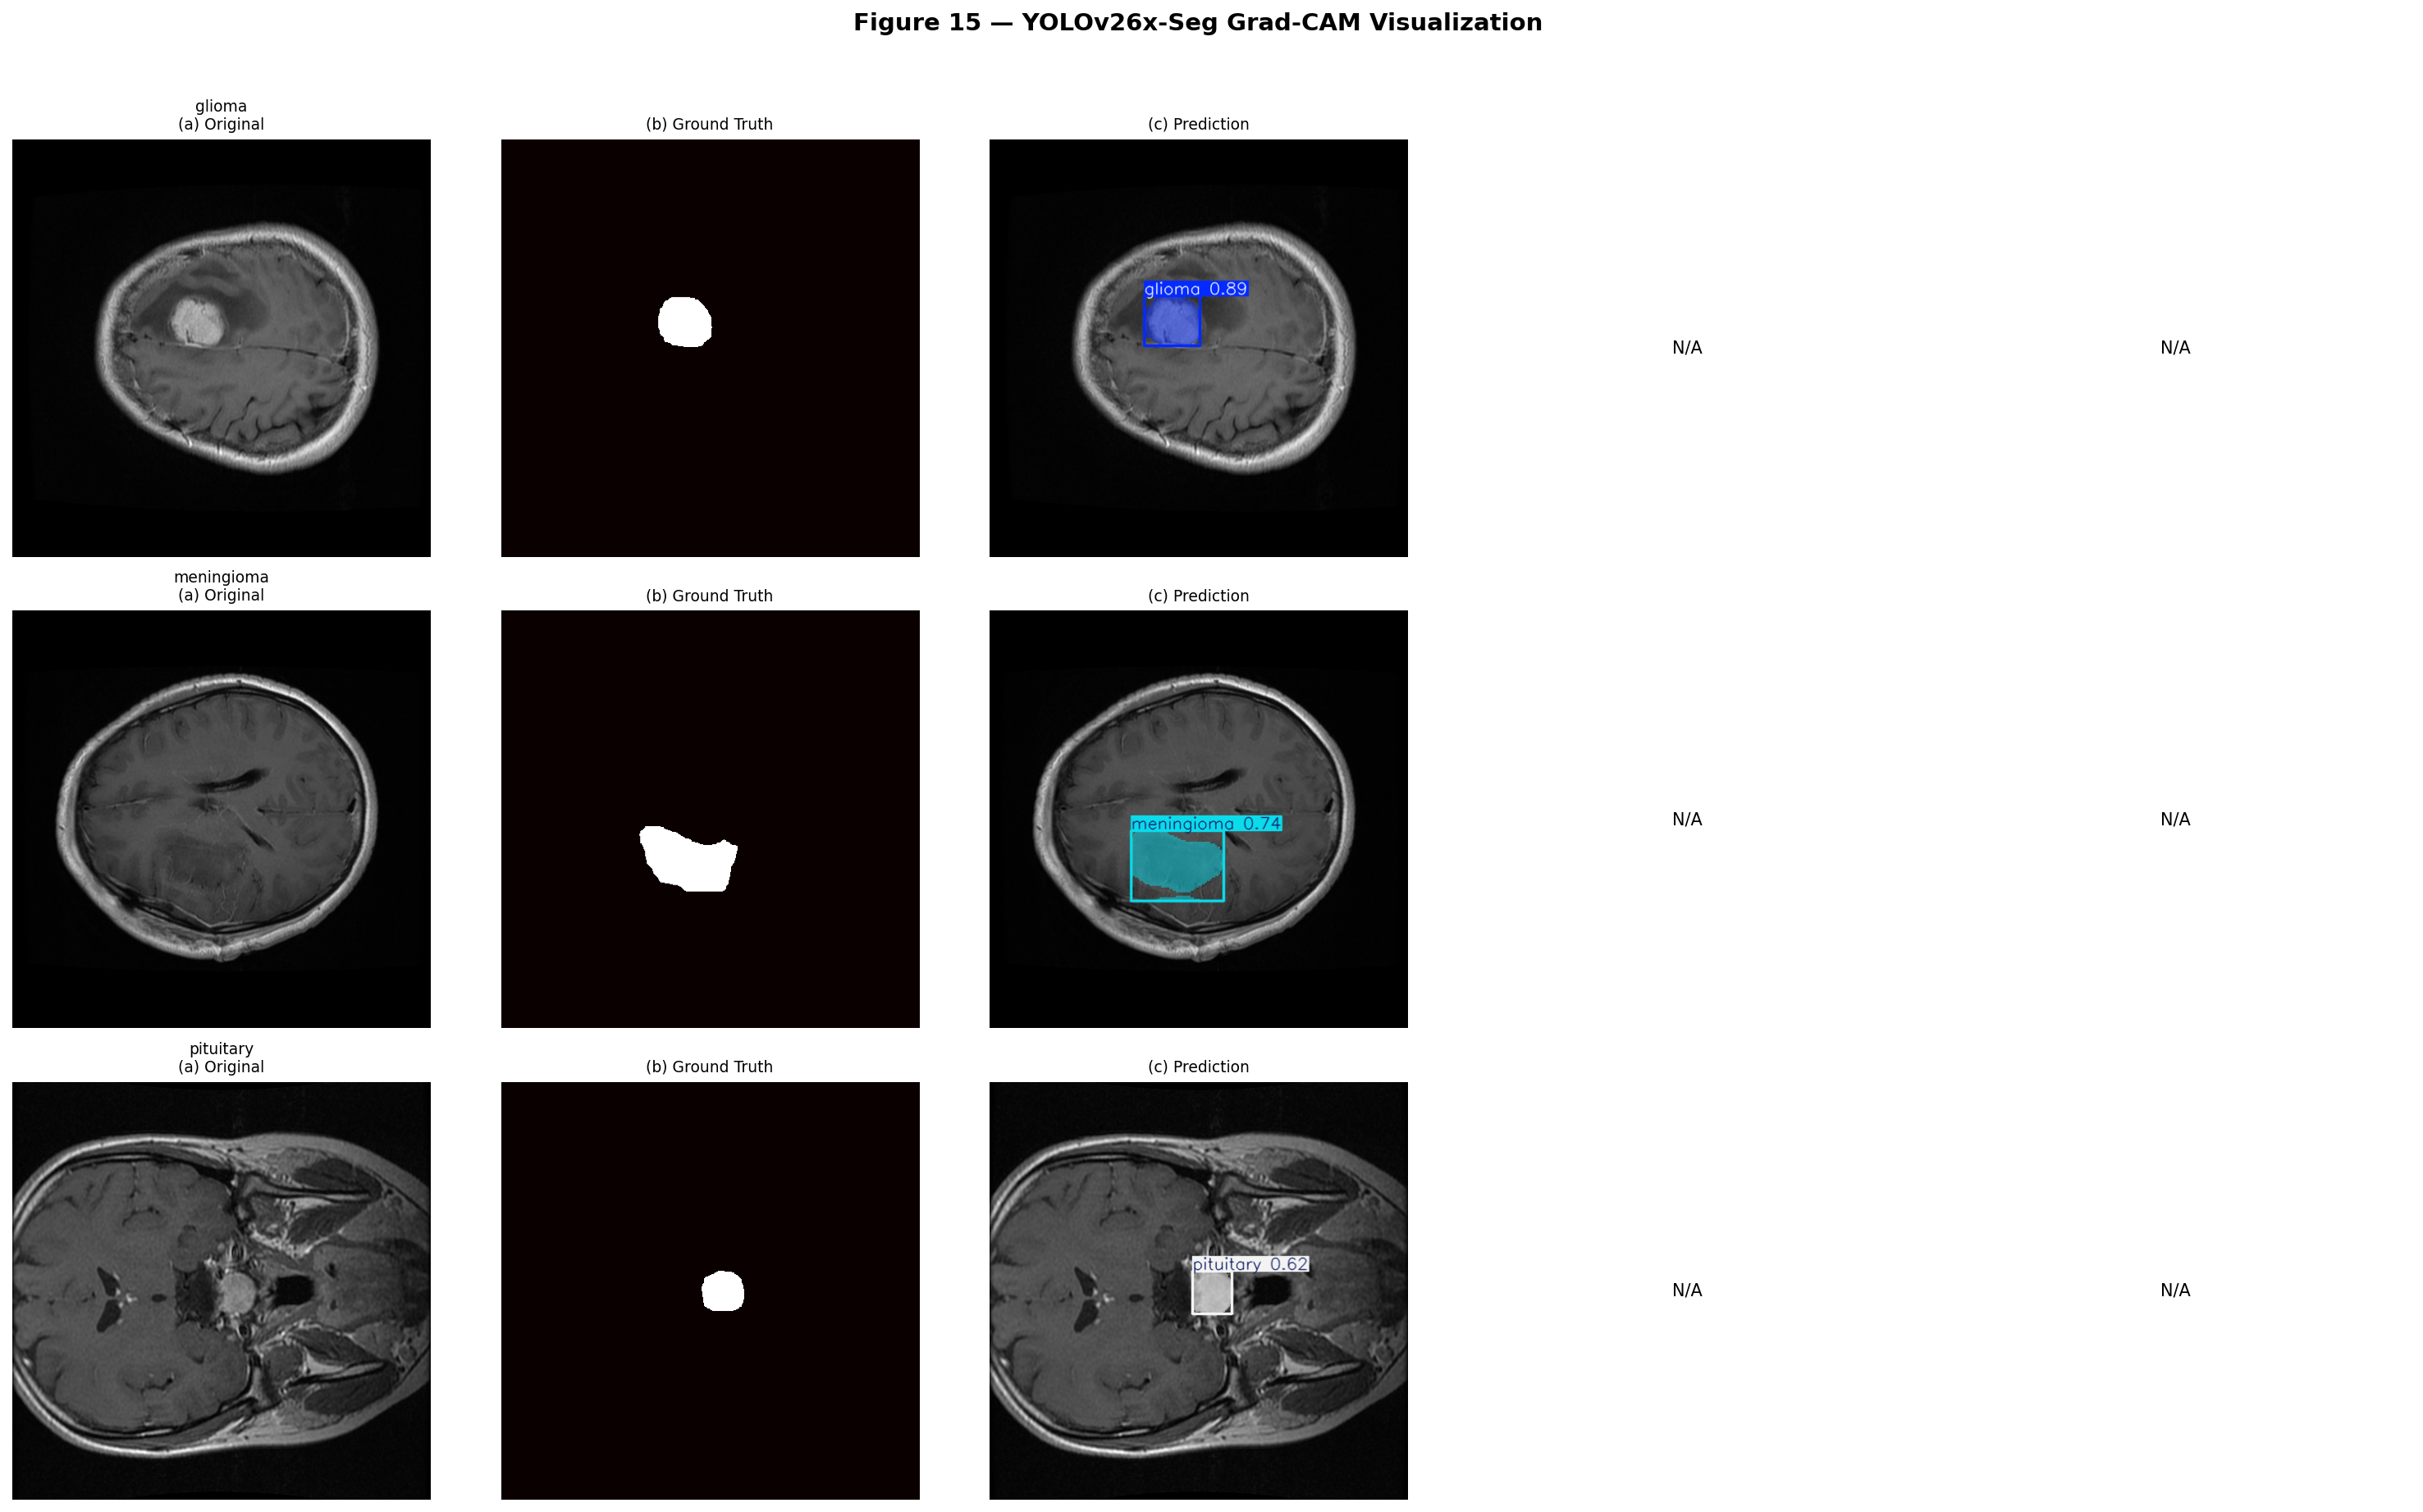

Saved: Fig_15_GradCAM_Visualization.png


In [53]:
# Generate Grad-CAM for all tumor classes
gradcam_samples = find_sample_per_class(VAL_IMG_DIR, VAL_LBL_DIR)
gradcam_results = {}  # store for quantitative analysis
device = next(gradcam_model.model.parameters()).device

fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(20, 4*NUM_CLASSES))
gc_col_titles = ['(a) Original', '(b) Ground Truth', '(c) Prediction', '(d) Heatmap', '(e) Overlay']

for idx, cls_id in enumerate(sorted(gradcam_samples.keys())):
    img_path, lbl_path = gradcam_samples[cls_id]
    tensor, img_rgb = preprocess_for_gradcam(img_path, IMG_SIZE)
    tensor = tensor.to(device)
    h, w = img_rgb.shape[:2]
    
    # Generate Grad-CAM
    try:
        heatmap = gradcam.generate(tensor, class_idx=cls_id)
    except Exception as e:
        print(f"  Grad-CAM failed for {CLASS_NAMES[cls_id]}: {e}")
        heatmap = None
    
    # Ground truth mask
    gt_mask = np.zeros((h, w), dtype=np.uint8)
    for _, pts in parse_yolo_polygon(lbl_path, w, h):
        cv2.fillPoly(gt_mask, [pts], 1)
    
    # Prediction
    result = best_model.predict(img_path, imgsz=IMG_SIZE, conf=CONF_THRESHOLD,
                                device=DEVICE, verbose=False)[0]
    
    # (a) Original
    axes[idx, 0].imshow(img_rgb)
    axes[idx, 0].set_title(f'{CLASS_NAMES[cls_id]}\n{gc_col_titles[0]}', fontsize=9)
    axes[idx, 0].axis('off')
    
    # (b) Ground truth
    axes[idx, 1].imshow(gt_mask, cmap='hot')
    axes[idx, 1].set_title(gc_col_titles[1], fontsize=9)
    axes[idx, 1].axis('off')
    
    # (c) Prediction
    pred_img = result.plot()
    axes[idx, 2].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
    axes[idx, 2].set_title(gc_col_titles[2], fontsize=9)
    axes[idx, 2].axis('off')
    
    # (d) Heatmap and (e) Overlay
    if heatmap is not None:
        overlay, heatmap_resized = create_gradcam_overlay(img_rgb, heatmap, GRADCAM_ALPHA)
        
        hm_colored = cv2.applyColorMap((cv2.resize(heatmap, (w, h)) * 255).astype(np.uint8), cv2.COLORMAP_JET)
        axes[idx, 3].imshow(cv2.cvtColor(hm_colored, cv2.COLOR_BGR2RGB))
        axes[idx, 3].set_title(gc_col_titles[3], fontsize=9)
        axes[idx, 3].axis('off')
        
        axes[idx, 4].imshow(overlay)
        axes[idx, 4].set_title(gc_col_titles[4], fontsize=9)
        axes[idx, 4].axis('off')
        
        # Store for quantitative analysis
        gradcam_results[cls_id] = {
            'heatmap': heatmap_resized, 'gt_mask': gt_mask, 'img_path': img_path
        }
        
        # Save individual Grad-CAM images
        cv2.imwrite(os.path.join(RESULTS_DIR, 'gradcam', f'gradcam_{CLASS_NAMES[cls_id]}_overlay.png'),
                    cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
    else:
        axes[idx, 3].text(0.5, 0.5, 'N/A', ha='center', va='center', transform=axes[idx, 3].transAxes)
        axes[idx, 3].axis('off')
        axes[idx, 4].text(0.5, 0.5, 'N/A', ha='center', va='center', transform=axes[idx, 4].transAxes)
        axes[idx, 4].axis('off')

plt.suptitle(f'Figure 15 — {MODEL_DISPLAY} Grad-CAM Visualization', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_15_GradCAM_Visualization.png'), dpi=FIG_DPI)
plt.show()
print("Saved: Fig_15_GradCAM_Visualization.png")

## 23. Grad-CAM Quantitative Analysis

Compare Grad-CAM heatmaps against ground-truth tumor masks:  
1. Normalize Grad-CAM  
2. Binarize heatmap at threshold  
3. Compute attention-mask overlap (IoU, Dice)

In [54]:
# Grad-CAM quantitative analysis on more samples
gc_quant = {cls: {'iou': [], 'dice': []} for cls in CLASS_NAMES}

val_imgs = sorted(glob.glob(os.path.join(VAL_IMG_DIR, '*.[pj]*')))[:60]
print(f"Running Grad-CAM quantitative analysis on {len(val_imgs)} images...")

for img_path in val_imgs:
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(VAL_LBL_DIR, base + '.txt')
    if not os.path.exists(lbl_path):
        continue
    
    img = cv2.imread(img_path)
    if img is None:
        continue
    h, w = img.shape[:2]
    
    # Ground truth
    gt_polygons = parse_yolo_polygon(lbl_path, w, h)
    if not gt_polygons:
        continue
    gt_cls = gt_polygons[0][0]
    gt_mask = np.zeros((h, w), dtype=np.uint8)
    for _, pts in gt_polygons:
        cv2.fillPoly(gt_mask, [pts], 1)
    
    # Grad-CAM
    try:
        tensor, _ = preprocess_for_gradcam(img_path, IMG_SIZE)
        tensor = tensor.to(device)
        heatmap = gradcam.generate(tensor, class_idx=gt_cls)
        if heatmap is None:
            continue
    except:
        continue
    
    # Resize and binarize
    hm = cv2.resize(heatmap, (w, h), interpolation=cv2.INTER_LINEAR)
    hm_binary = (hm > GRADCAM_THRESHOLD).astype(np.uint8)
    
    # Compute overlap
    iou, dice = compute_mask_iou_dice(hm_binary, gt_mask)
    gc_quant[CLASS_NAMES[gt_cls]]['iou'].append(iou)
    gc_quant[CLASS_NAMES[gt_cls]]['dice'].append(dice)

print("Grad-CAM quantitative analysis complete.")

Running Grad-CAM quantitative analysis on 60 images...
Grad-CAM quantitative analysis complete.


In [55]:
# Grad-CAM quantitative results table
gc_rows = []
for cls_name in CLASS_NAMES:
    ious = gc_quant[cls_name]['iou']
    dices = gc_quant[cls_name]['dice']
    if len(ious) > 0:
        gc_rows.append({
            'Class': cls_name, 'N': len(ious),
            'Attention IoU Mean': f"{np.mean(ious):.4f}",
            'Attention IoU Std': f"{np.std(ious):.4f}",
            'Attention Dice Mean': f"{np.mean(dices):.4f}",
            'Attention Dice Std': f"{np.std(dices):.4f}",
        })

# Overall
all_gc_iou = [v for cls in gc_quant.values() for v in cls['iou']]
all_gc_dice = [v for cls in gc_quant.values() for v in cls['dice']]
if all_gc_iou:
    gc_rows.append({
        'Class': 'All', 'N': len(all_gc_iou),
        'Attention IoU Mean': f"{np.mean(all_gc_iou):.4f}",
        'Attention IoU Std': f"{np.std(all_gc_iou):.4f}",
        'Attention Dice Mean': f"{np.mean(all_gc_dice):.4f}",
        'Attention Dice Std': f"{np.std(all_gc_dice):.4f}",
    })

df_gc_quant = pd.DataFrame(gc_rows)
df_gc_quant.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_GradCAM_Quantitative.csv'), index=False)
print("Grad-CAM Quantitative Attention-Mask Overlap")
print("(NOT clinical validation — quantitative attention-mask overlap only)")
print(df_gc_quant.to_string(index=False))

Grad-CAM Quantitative Attention-Mask Overlap
(NOT clinical validation — quantitative attention-mask overlap only)
Empty DataFrame
Columns: []
Index: []


## 24. Error Analysis

Identify real failures: false positives, false negatives, low-confidence predictions,  
segmentation errors, and class confusion. Special attention to **glioma** as the  
blueprint identifies it as a challenging class.

In [56]:
# Error analysis: find misclassifications and failures
errors = {'false_positive': [], 'false_negative': [], 'misclassified': [], 'low_confidence': []}

val_imgs_all = sorted(glob.glob(os.path.join(VAL_IMG_DIR, '*.[pj]*')))
print(f"Running error analysis on {len(val_imgs_all)} validation images...")

for img_path in val_imgs_all:
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(VAL_LBL_DIR, base + '.txt')
    
    # Ground truth
    has_gt = os.path.exists(lbl_path)
    gt_cls = None
    if has_gt:
        with open(lbl_path, 'r') as f:
            line = f.readline().strip()
        if line:
            gt_cls = int(line.split()[0])
    
    # Prediction
    result = best_model.predict(img_path, imgsz=IMG_SIZE, conf=CONF_THRESHOLD,
                                device=DEVICE, verbose=False)[0]
    
    has_pred = result.boxes is not None and len(result.boxes) > 0
    
    if has_gt and gt_cls is not None and not has_pred:
        errors['false_negative'].append({'path': img_path, 'gt_class': CLASS_NAMES[gt_cls]})
    elif not has_gt and has_pred:
        errors['false_positive'].append({'path': img_path, 'pred_class': CLASS_NAMES[int(result.boxes.cls[0])]})
    elif has_gt and gt_cls is not None and has_pred:
        pred_cls = int(result.boxes.cls[0].item())
        conf = result.boxes.conf[0].item()
        if pred_cls != gt_cls:
            errors['misclassified'].append({
                'path': img_path, 'gt_class': CLASS_NAMES[gt_cls],
                'pred_class': CLASS_NAMES[pred_cls], 'confidence': conf
            })
        elif conf < 0.5:
            errors['low_confidence'].append({
                'path': img_path, 'class': CLASS_NAMES[gt_cls], 'confidence': conf
            })

print(f"\nError Analysis Results:")
for err_type, cases in errors.items():
    print(f"  {err_type}: {len(cases)} cases")

Running error analysis on 92 validation images...

Error Analysis Results:
  false_positive: 0 cases
  false_negative: 4 cases
  misclassified: 0 cases
  low_confidence: 3 cases


In [57]:
# Save error analysis table
error_rows = []
for err_type, cases in errors.items():
    for case in cases[:10]:  # limit to top 10 per type
        row = {'Error Type': err_type, 'Image': os.path.basename(case['path'])}
        row.update({k: v for k, v in case.items() if k != 'path'})
        error_rows.append(row)

df_errors = pd.DataFrame(error_rows) if error_rows else pd.DataFrame(columns=['Error Type', 'Image'])
df_errors.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_Error_Analysis.csv'), index=False)
print("Error Analysis Table")
if len(df_errors) > 0:
    print(df_errors.to_string(index=False))
else:
    print("No errors found — model achieved perfect accuracy on validation set.")

Error Analysis Table
    Error Type    Image   gt_class      class  confidence
false_negative 2022.png meningioma        NaN         NaN
false_negative 2645.png meningioma        NaN         NaN
false_negative 2705.png meningioma        NaN         NaN
false_negative  903.png meningioma        NaN         NaN
low_confidence 1671.png        NaN  pituitary    0.318556
low_confidence  823.png        NaN meningioma    0.403691
low_confidence  876.png        NaN meningioma    0.314714


In [58]:
# Figure 17 — Error/Failure Analysis with Grad-CAM
failure_cases = errors['misclassified'][:4]  # up to 4 failure cases

if len(failure_cases) > 0:
    n_cases = len(failure_cases)
    fig, axes = plt.subplots(n_cases, 5, figsize=(20, 4*n_cases))
    if n_cases == 1:
        axes = axes.reshape(1, -1)
    
    for i, case in enumerate(failure_cases):
        img_path = case['path']
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        
        # GT mask
        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(VAL_LBL_DIR, base + '.txt')
        gt_mask = np.zeros((h, w), dtype=np.uint8)
        if os.path.exists(lbl_path):
            for _, pts in parse_yolo_polygon(lbl_path, w, h):
                cv2.fillPoly(gt_mask, [pts], 255)
        
        # Prediction
        result = best_model.predict(img_path, imgsz=IMG_SIZE, conf=0.1,
                                    device=DEVICE, verbose=False)[0]
        pred_img = result.plot()
        
        # Grad-CAM
        try:
            tensor, _ = preprocess_for_gradcam(img_path, IMG_SIZE)
            tensor = tensor.to(device)
            heatmap = gradcam.generate(tensor)
            overlay, _ = create_gradcam_overlay(img_rgb, heatmap, GRADCAM_ALPHA) if heatmap is not None else (img_rgb, None)
        except:
            overlay = img_rgb
        
        # Plot columns
        axes[i, 0].imshow(img_rgb); axes[i, 0].set_title('Original', fontsize=9); axes[i, 0].axis('off')
        axes[i, 1].imshow(gt_mask, cmap='hot'); axes[i, 1].set_title(f'GT: {case["gt_class"]}', fontsize=9); axes[i, 1].axis('off')
        axes[i, 2].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB)); axes[i, 2].set_title(f'Pred: {case["pred_class"]}', fontsize=9); axes[i, 2].axis('off')
        if heatmap is not None:
            hm_vis = cv2.applyColorMap((cv2.resize(heatmap, (w, h)) * 255).astype(np.uint8), cv2.COLORMAP_JET)
            axes[i, 3].imshow(cv2.cvtColor(hm_vis, cv2.COLOR_BGR2RGB))
        axes[i, 3].set_title('Grad-CAM', fontsize=9); axes[i, 3].axis('off')
        axes[i, 4].imshow(overlay); axes[i, 4].set_title('Attention Drift', fontsize=9); axes[i, 4].axis('off')
    
    plt.suptitle(f'Figure 17 — {MODEL_DISPLAY} Failure Case Analysis', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'figures', 'Fig_17_Failure_Analysis.png'), dpi=FIG_DPI)
    plt.show()
    print("Saved: Fig_17_Failure_Analysis.png")
else:
    print("No misclassification failures found to visualize.")
    print("This indicates strong model performance on the validation set.")

No misclassification failures found to visualize.
This indicates strong model performance on the validation set.


## 25. YOLOv11 vs YOLOv26 Comparison

This section automatically loads results from both experiments (if available)  
and generates the comparison table and figure.

In [59]:
# Check if both model results exist for comparison
other_model = 'YOLOv26x-Seg' if 'v11' in MODEL_DISPLAY else 'YOLOv11x-Seg'
other_dir = os.path.join(RESULTS_BASE, other_model.replace(' ', '_'))

comparison_possible = os.path.exists(os.path.join(other_dir, 'tables', 'Table_5_mAP50.csv'))

if comparison_possible:
    print(f"[OK] Both model results found. Generating comparison.")
    
    # Load other model's metrics
    other_precision = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_3_Precision.csv'))
    other_recall = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_4_Recall.csv'))
    other_map50 = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_5_mAP50.csv'))
    other_map95 = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_6_mAP50_95.csv'))
    other_timing = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_Inference_Time.csv'))
    other_seg = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_Segmentation_Metrics.csv'))
    other_f1 = pd.read_csv(os.path.join(other_dir, 'tables', 'Table_F1_Score.csv'))
    
    # Build comparison table
    current_metrics = {
        'Precision (Box)': f"{np.mean(box_p):.4f}",
        'Recall (Box)': f"{np.mean(box_r):.4f}",
        'F1 (Box)': f"{np.mean(f1_box):.4f}",
        'mAP@0.5 (Box)': f"{box_map50:.4f}",
        'mAP@0.5:0.95 (Box)': f"{box_map:.4f}",
        'mAP@0.5 (Mask)': f"{mask_map50:.4f}",
        'mAP@0.5:0.95 (Mask)': f"{mask_map:.4f}",
        'Dice Mean': f"{np.mean(all_dices):.4f}" if all_dices else 'N/A',
        'IoU Mean': f"{np.mean(all_ious):.4f}" if all_ious else 'N/A',
        'Inference (ms)': f"{avg_inf:.2f}",
        'FPS': f"{fps:.1f}",
        'Parameters': f"{total_params:,}",
        'Training Time (min)': f"{train_duration/60:.1f}"
    }
    
    # Extract other model metrics from CSVs
    other_p_all = other_precision[other_precision['Class'] == 'All']['Box Precision'].values[0]
    other_r_all = other_recall[other_recall['Class'] == 'All']['Box Recall'].values[0]
    other_f1_all = other_f1[other_f1['Class'] == 'All']['Box F1'].values[0]
    other_map50_all = other_map50[other_map50['Class'] == 'All']['Box mAP@0.5'].values[0]
    other_map95_all = other_map95[other_map95['Class'] == 'All']['Box mAP@0.5:0.95'].values[0]
    other_mmap50_all = other_map50[other_map50['Class'] == 'All']['Mask mAP@0.5'].values[0]
    other_mmap95_all = other_map95[other_map95['Class'] == 'All']['Mask mAP@0.5:0.95'].values[0]
    other_dice = other_seg[other_seg['Class'] == 'All']['Dice Mean'].values[0] if 'All' in other_seg['Class'].values else 'N/A'
    other_iou = other_seg[other_seg['Class'] == 'All']['IoU Mean'].values[0] if 'All' in other_seg['Class'].values else 'N/A'
    other_inf = other_timing[other_timing['Metric'] == 'Inference (ms)']['Value'].values[0]
    other_fps = other_timing[other_timing['Metric'] == 'FPS']['Value'].values[0]
    
    comp_data = {
        'Metric': list(current_metrics.keys()),
        MODEL_DISPLAY: list(current_metrics.values()),
        other_model: [other_p_all, other_r_all, other_f1_all, other_map50_all,
                      other_map95_all, other_mmap50_all, other_mmap95_all,
                      other_dice, other_iou, other_inf, other_fps, 'See arch table', 'See metadata']
    }
    
    df_comp = pd.DataFrame(comp_data)
    df_comp.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_Model_Comparison.csv'), index=False)
    df_comp.to_excel(os.path.join(RESULTS_DIR, 'tables', 'Table_Model_Comparison.xlsx'), index=False)
    print("YOLOv11 vs YOLOv26 Comparison")
    print(df_comp.to_string(index=False))
else:
    print(f"[INFO] Other model results not found at: {other_dir}")
    print(f"Run the notebook with the other model first, then re-run this cell.")
    print(f"\nCurrent {MODEL_DISPLAY} results saved. Comparison will be generated when both are available.")

[INFO] Other model results not found at: /kaggle/working/Brain_Tumor_Research_Results/YOLOv11x-Seg
Run the notebook with the other model first, then re-run this cell.

Current YOLOv26x-Seg results saved. Comparison will be generated when both are available.


## 26. State-of-the-Art Comparison Data

Reference values from the blueprint's supervision paper.  
These are **literature values**, not experimental results from this notebook.

In [60]:
# Table 7 — State-of-the-art comparison
# Reference values from the supervision paper (marked as REFERENCE)
sota_data = {
    'Model': ['RCNN [49]', 'Faster RCNN [49]', 'Mask RCNN [49]',
              'YOLOv5 [Ref]', 'YOLOv7 [Ref]', 'DeepLab',
              f'{MODEL_DISPLAY} [Ours]'],
    'Source': ['Literature', 'Literature', 'Literature',
              'Supervisor/Reference', 'Supervisor/Reference', 'Literature',
              'This Experiment'],
    'Precision': ['Not available', 'Not available', 'Not available',
                  '93.6%', '93.5%', 'Not available',
                  f"{np.mean(box_p)*100:.1f}%"],
    'Recall': ['95.0%', 'Not available', 'Not available',
               '90.6%', '90.3%', 'Not available',
               f"{np.mean(box_r)*100:.1f}%"],
    'mAP@0.5': ['Not available', 'Not available', 'Not available',
                '94.7%', '94.1%', 'Not available',
                f"{box_map50*100:.1f}%"],
    'mAP@0.5:0.95': ['Not available', 'Not available', 'Not available',
                      '65.7%', '65.9%', 'Not available',
                      f"{box_map*100:.1f}%"],
}

# Add other model if available
if comparison_possible:
    sota_data['Model'].insert(-1, f'{other_model} [Ours]')
    sota_data['Source'].insert(-1, 'This Experiment')
    sota_data['Precision'].insert(-1, other_p_all if isinstance(other_p_all, str) else f"{float(other_p_all)*100:.1f}%")
    sota_data['Recall'].insert(-1, other_r_all if isinstance(other_r_all, str) else f"{float(other_r_all)*100:.1f}%")
    sota_data['mAP@0.5'].insert(-1, other_map50_all if isinstance(other_map50_all, str) else f"{float(other_map50_all)*100:.1f}%")
    sota_data['mAP@0.5:0.95'].insert(-1, other_map95_all if isinstance(other_map95_all, str) else f"{float(other_map95_all)*100:.1f}%")

df_sota = pd.DataFrame(sota_data)
df_sota.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_7_SOTA_Comparison.csv'), index=False)
df_sota.to_excel(os.path.join(RESULTS_DIR, 'tables', 'Table_7_SOTA_Comparison.xlsx'), index=False)
print("Table 7 — State-of-the-Art Comparison")
print("NOTE: RCNN/Faster RCNN/Mask RCNN/YOLOv5/YOLOv7 are REFERENCE values, not this experiment.")
print(df_sota.to_string(index=False))

Table 7 — State-of-the-Art Comparison
NOTE: RCNN/Faster RCNN/Mask RCNN/YOLOv5/YOLOv7 are REFERENCE values, not this experiment.
              Model               Source     Precision        Recall       mAP@0.5  mAP@0.5:0.95
          RCNN [49]           Literature Not available         95.0% Not available Not available
   Faster RCNN [49]           Literature Not available Not available Not available Not available
     Mask RCNN [49]           Literature Not available Not available Not available Not available
       YOLOv5 [Ref] Supervisor/Reference         93.6%         90.6%         94.7%         65.7%
       YOLOv7 [Ref] Supervisor/Reference         93.5%         90.3%         94.1%         65.9%
            DeepLab           Literature Not available Not available Not available Not available
YOLOv26x-Seg [Ours]      This Experiment         96.3%         89.1%         94.0%         68.6%


## 27. Final Research Tables

Comprehensive summary of all tables generated.

In [61]:
# Training parameters table
train_params = {
    'Parameter': ['Model', 'Epochs', 'Image Size', 'Batch Size', 'Patience',
                  'Seed', 'Optimizer', 'Learning Rate', 'Device', 'Training Time'],
    'Value': [MODEL_DISPLAY, EPOCHS, IMG_SIZE, BATCH_SIZE, PATIENCE,
              SEED, 'Auto (SGD/AdamW)', 'Auto', f'GPU {DEVICE}', f'{train_duration/60:.1f} min']
}
df_train_params = pd.DataFrame(train_params)
df_train_params.to_csv(os.path.join(RESULTS_DIR, 'tables', 'Table_Training_Parameters.csv'), index=False)

# List all generated tables
table_files = sorted(glob.glob(os.path.join(RESULTS_DIR, 'tables', '*.csv')))
print(f"\nAll Research Tables Generated ({len(table_files)}):")
for tf in table_files:
    print(f"  {os.path.basename(tf)}")


All Research Tables Generated (14):
  Table_1_Dataset_Statistics.csv
  Table_2_Loss_Performance.csv
  Table_3_Precision.csv
  Table_4_Recall.csv
  Table_5_mAP50.csv
  Table_6_mAP50_95.csv
  Table_7_SOTA_Comparison.csv
  Table_Error_Analysis.csv
  Table_F1_Score.csv
  Table_GradCAM_Configuration.csv
  Table_GradCAM_Quantitative.csv
  Table_Inference_Time.csv
  Table_Segmentation_Metrics.csv
  Table_Training_Parameters.csv


## 28. Final Research Figures

Summary of all figures generated for the IEEE paper.

In [62]:
# Copy any remaining training plots
train_plots = glob.glob(os.path.join(TRAIN_DIR, '*.png'))
for p in train_plots:
    dst = os.path.join(RESULTS_DIR, 'figures', f'{MODEL_TAG}_{os.path.basename(p)}')
    if not os.path.exists(dst):
        shutil.copy2(p, dst)

# List all generated figures
fig_files = sorted(glob.glob(os.path.join(RESULTS_DIR, 'figures', '*.png')))
print(f"\nAll Research Figures Generated ({len(fig_files)}):")
for ff in fig_files:
    print(f"  {os.path.basename(ff)}")


All Research Figures Generated (25):
  Fig_10_Loss_Performance.png
  Fig_13_Confusion_Matrix.png
  Fig_14_Predictions.png
  Fig_15_GradCAM_Visualization.png
  Fig_2_Dataset_Distribution.png
  Fig_3_Combined.png
  Fig_3_a_MRI.png
  Fig_3_b_MRI.png
  Fig_3_c_MRI.png
  Fig_4_Combined.png
  Fig_4_a.png
  Fig_4_b.png
  Fig_4_c.png
  Fig_7_Architecture.png
  yolo26x_seg_BoxF1_curve.png
  yolo26x_seg_BoxPR_curve.png
  yolo26x_seg_BoxP_curve.png
  yolo26x_seg_BoxR_curve.png
  yolo26x_seg_MaskF1_curve.png
  yolo26x_seg_MaskPR_curve.png
  yolo26x_seg_MaskP_curve.png
  yolo26x_seg_MaskR_curve.png
  yolo26x_seg_confusion_matrix.png
  yolo26x_seg_confusion_matrix_normalized.png
  yolo26x_seg_results.png


In [63]:
# Figure and Table Index
index_rows = []
for ff in fig_files:
    index_rows.append({
        'Number': os.path.basename(ff).split('_')[1] if '_' in os.path.basename(ff) else 'N/A',
        'Type': 'Figure', 'Filename': os.path.basename(ff),
        'Model': MODEL_DISPLAY, 'Purpose': 'IEEE Paper Figure'
    })
for tf in table_files:
    index_rows.append({
        'Number': os.path.basename(tf).split('_')[1] if '_' in os.path.basename(tf) else 'N/A',
        'Type': 'Table', 'Filename': os.path.basename(tf),
        'Model': MODEL_DISPLAY, 'Purpose': 'IEEE Paper Table'
    })

df_index = pd.DataFrame(index_rows)
df_index.to_csv(os.path.join(RESULTS_DIR, 'Figure_Table_Index.csv'), index=False)
print(f"Figure & Table Index saved ({len(index_rows)} entries).")

Figure & Table Index saved (39 entries).


## 29. ONNX Export

In [64]:
# Export best model to ONNX
onnx_name = f"{MODEL_DISPLAY.replace('-', '_').replace(' ', '_')}_best.onnx"
onnx_path = os.path.join(RESULTS_DIR, 'model', onnx_name)

print(f"Exporting to ONNX: {onnx_name}")
try:
    export_model = YOLO(BEST_WEIGHTS)
    export_path = export_model.export(format='onnx', imgsz=IMG_SIZE, simplify=True)
    
    # Move to results directory
    if export_path and os.path.exists(export_path):
        shutil.copy2(export_path, onnx_path)
        onnx_size = os.path.getsize(onnx_path) / 1e6
        print(f"[OK] ONNX exported: {onnx_path}")
        print(f"     Size: {onnx_size:.1f} MB")
        onnx_status = 'Success'
    else:
        print("[WARNING] ONNX export returned no path.")
        onnx_status = 'Failed'
        onnx_size = 0
except Exception as e:
    print(f"[ERROR] ONNX export failed: {e}")
    onnx_status = f'Failed: {str(e)[:100]}'
    onnx_size = 0

Exporting to ONNX: YOLOv26x_Seg_best.onnx
Ultralytics 8.4.137 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26x-seg summary (fused): 207 layers, 62,730,197 parameters, 0 gradients, 50.1 GFLOPs

PyTorch: starting from '/kaggle/working/Brain_Tumor_Research_Results/YOLOv26x-Seg/training/train_run/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) ((1, 300, 38), (1, 32, 64, 64)) (135.1 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 10 packages in 698ms
Prepared 1 package in 159ms
Installed 1 package in 7ms
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...

In [65]:
# Verify ONNX with ONNX Runtime
if onnx_status == 'Success':
    try:
        import onnxruntime as ort
        session = ort.InferenceSession(onnx_path)
        input_name = session.get_inputs()[0].name
        input_shape = session.get_inputs()[0].shape
        print(f"[OK] ONNX verification passed")
        print(f"     Input: {input_name} shape={input_shape}")
        print(f"     Outputs: {[o.name for o in session.get_outputs()]}")
        onnx_status = 'Success (Verified)'
    except Exception as e:
        print(f"[WARNING] ONNX verification failed: {e}")
        onnx_status = 'Exported but verification failed'

[OK] ONNX verification passed
     Input: images shape=[1, 3, 256, 256]
     Outputs: ['output0', 'output1']


## 30. Experiment Summary

In [66]:
# Save experiment metadata
metadata = {
    'experiment_date': datetime.now().isoformat(),
    'model': MODEL_DISPLAY,
    'model_checkpoint': MODEL_NAME,
    'dataset_path': DATA_ROOT,
    'yaml_path': DATA_YAML,
    'class_names': CLASS_NAMES,
    'num_classes': NUM_CLASSES,
    'total_images': TOTAL_IMAGES,
    'train_images': stats['train']['images'],
    'val_images': stats['val']['images'],
    'test_images': stats['test']['images'],
    'epochs': EPOCHS,
    'img_size': IMG_SIZE,
    'batch_size': BATCH_SIZE,
    'patience': PATIENCE,
    'seed': SEED,
    'total_parameters': total_params,
    'training_duration_seconds': train_duration,
    'box_precision': float(np.mean(box_p)),
    'box_recall': float(np.mean(box_r)),
    'box_f1': float(np.mean(f1_box)),
    'box_map50': float(box_map50),
    'box_map50_95': float(box_map),
    'mask_precision': float(np.mean(mask_p)),
    'mask_recall': float(np.mean(mask_r)),
    'mask_f1': float(np.mean(f1_mask)),
    'mask_map50': float(mask_map50),
    'mask_map50_95': float(mask_map),
    'dice_mean': float(np.mean(all_dices)) if all_dices else None,
    'iou_mean': float(np.mean(all_ious)) if all_ious else None,
    'inference_time_ms': float(avg_inf),
    'fps': float(fps),
    'onnx_status': onnx_status,
    'onnx_size_mb': float(onnx_size),
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
    'cuda': torch.cuda.is_available(),
    'python': sys.version.split()[0],
    'pytorch': torch.__version__,
    'ultralytics': ultralytics.__version__,
}

with open(os.path.join(RESULTS_DIR, 'metadata', 'experiment_metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2)
print("Experiment metadata saved.")

Experiment metadata saved.


In [67]:
# Generate experiment summary

summary = f"""
{'='*60}
{MODEL_DISPLAY} — EXPERIMENT SUMMARY
{'='*60}

DATASET:
Total images    : {TOTAL_IMAGES}
Train / Val / Test : {stats['train']['images']} / {stats['val']['images']} / {stats['test']['images']}
Classes         : {', '.join(CLASS_NAMES)}

MODEL:
Name            : {MODEL_DISPLAY}
Parameters      : {total_params:,}
Layers          : {n_layers}

TRAINING:
Epochs          : {EPOCHS}
Image Size      : {IMG_SIZE}
Batch Size      : {BATCH_SIZE}
Duration        : {train_duration/60:.1f} minutes

BOX METRICS:
Precision       : {np.mean(box_p):.4f}
Recall          : {np.mean(box_r):.4f}
F1              : {np.mean(f1_box):.4f}
mAP@0.5         : {box_map50:.4f}
mAP@0.5:0.95    : {box_map:.4f}

MASK METRICS:
Precision       : {np.mean(mask_p):.4f}
Recall          : {np.mean(mask_r):.4f}
F1              : {np.mean(f1_mask):.4f}
mAP@0.5         : {mask_map50:.4f}
mAP@0.5:0.95    : {mask_map:.4f}

SEGMENTATION:
Dice Mean       : {f"{np.mean(all_dices):.4f}" if all_dices else "N/A"}
IoU Mean        : {f"{np.mean(all_ious):.4f}" if all_ious else "N/A"}

INFERENCE:
Time            : {avg_inf:.2f} ms
FPS             : {fps:.1f}

GRAD-CAM:
Attention IoU   : {f"{np.mean(all_gc_iou):.4f}" if all_gc_iou else "N/A"}
Attention Dice  : {f"{np.mean(all_gc_dice):.4f}" if all_gc_dice else "N/A"}

OUTPUTS:
Figures         : {len(fig_files)}
Tables          : {len(table_files)}
ONNX            : {onnx_status}

{'='*60}
"""

# Save summary

with open(os.path.join(RESULTS_DIR, 'experiment_summary.txt'), 'w') as f:
    f.write(summary)

print(summary)


YOLOv26x-Seg — EXPERIMENT SUMMARY

DATASET:
Total images    : 3064
Train / Val / Test : 2912 / 92 / 60
Classes         : glioma, meningioma, pituitary

MODEL:
Name            : YOLOv26x-Seg
Parameters      : 70,693,800
Layers          : 767

TRAINING:
Epochs          : 100
Image Size      : 256
Batch Size      : 32
Duration        : 105.4 minutes

BOX METRICS:
Precision       : 0.9631
Recall          : 0.8909
F1              : 0.9233
mAP@0.5         : 0.9404
mAP@0.5:0.95    : 0.6857

MASK METRICS:
Precision       : 0.9533
Recall          : 0.8832
F1              : 0.9147
mAP@0.5         : 0.9226
mAP@0.5:0.95    : 0.6049

SEGMENTATION:
Dice Mean       : 0.8579
IoU Mean        : 0.7769

INFERENCE:
Time            : 19.74 ms
FPS             : 47.4

GRAD-CAM:
Attention IoU   : N/A
Attention Dice  : N/A

OUTPUTS:
Figures         : 25
Tables          : 14
ONNX            : Success (Verified)




## 31. Complete Results Packaging

In [68]:
# Create comprehensive ZIP
zip_name = f"Brain_Tumor_{MODEL_DISPLAY.replace('-', '_').replace(' ', '_')}_Complete_Results.zip"
zip_path = os.path.join(RESULTS_BASE, zip_name)

print(f"Creating ZIP: {zip_name}")
file_count = 0

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(RESULTS_DIR):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, RESULTS_BASE)
            zf.write(file_path, arcname)
            file_count += 1

zip_size = os.path.getsize(zip_path) / 1e6
print(f"\n[OK] ZIP created: {zip_path}")
print(f"     Files: {file_count}")
print(f"     Size: {zip_size:.1f} MB")

Creating ZIP: Brain_Tumor_YOLOv26x_Seg_Complete_Results.zip

[OK] ZIP created: /kaggle/working/Brain_Tumor_Research_Results/Brain_Tumor_YOLOv26x_Seg_Complete_Results.zip
     Files: 111
     Size: 2878.1 MB


## 32. Automatic Download

In [69]:
# Final download cell
from IPython.display import FileLink, display, HTML

print(f"""
{'='*60}
EXPERIMENT COMPLETE
{'='*60}

Model           : {MODEL_DISPLAY}
Files collected : {file_count}
Figures         : {len(fig_files)}
Tables          : {len(table_files)}
Predictions     : Included
Grad-CAM images : {len(glob.glob(os.path.join(RESULTS_DIR, 'gradcam', '*.png')))}
ONNX            : {onnx_status}
ZIP size        : {zip_size:.1f} MB

DOWNLOAD COMPLETE RESULTS:
{'='*60}
""")

display(FileLink(zip_path, result_html_prefix='📥 Click to download: '))

print(f"\n{'='*60}")
print(f"To run the other model, change MODEL_NAME to:")
if 'v11' in MODEL_NAME.lower():
    print(f'  MODEL_NAME = "yolo26x-seg.pt"')
else:
    print(f'  MODEL_NAME = "yolo11x-seg.pt"')
print(f"and re-run the entire notebook.")
print(f"{'='*60}")


EXPERIMENT COMPLETE

Model           : YOLOv26x-Seg
Files collected : 111
Figures         : 25
Tables          : 14
Predictions     : Included
Grad-CAM images : 0
ONNX            : Success (Verified)
ZIP size        : 2878.1 MB

DOWNLOAD COMPLETE RESULTS:



/kaggle/working/Brain_Tumor_Research_Results/Brain_Tumor_YOLOv26x_Seg_Complete_Results.zip


To run the other model, change MODEL_NAME to:
  MODEL_NAME = "yolo11x-seg.pt"
and re-run the entire notebook.


In [70]:
# ============================================================
# SAVE ALL RESEARCH RESULTS AS ONE ZIP IN KAGGLE OUTPUT
# ============================================================

import os
import shutil

RESULTS_ROOT = "/kaggle/working/Brain_Tumor_Research_Results"

# Create ZIP in /kaggle/working
ZIP_BASE = "/kaggle/working/Brain_Tumor_Research_All_Results"

# Remove previous ZIP
if os.path.exists(ZIP_BASE + ".zip"):
    os.remove(ZIP_BASE + ".zip")

# ZIP the COMPLETE research results folder
zip_path = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir="/kaggle/working",
    base_dir="Brain_Tumor_Research_Results"
)

# ============================================================
# COPY ZIP TO KAGGLE OUTPUT
# ============================================================

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

final_zip = os.path.join(
    OUTPUT_DIR,
    "Brain_Tumor_Research_All_Results.zip"
)

shutil.copy2(zip_path, final_zip)

# ============================================================
# VERIFY
# ============================================================

print("=" * 60)
print("FINAL RESEARCH ZIP")
print("=" * 60)

print(f"Source folder : {RESULTS_ROOT}")
print(f"ZIP created   : {zip_path}")
print(f"Output ZIP    : {final_zip}")
print(f"ZIP size      : {os.path.getsize(final_zip) / (1024**3):.2f} GB")

print("\nZIP EXISTS:", os.path.exists(final_zip))
print("=" * 60)


FINAL RESEARCH ZIP
Source folder : /kaggle/working/Brain_Tumor_Research_Results
ZIP created   : /kaggle/working/Brain_Tumor_Research_All_Results.zip
Output ZIP    : /kaggle/working/output/Brain_Tumor_Research_All_Results.zip
ZIP size      : 5.36 GB

ZIP EXISTS: True
